In [1]:
########################################
## COLAB CLONE REPOSITORY FROM GITHUB ##
########################################

## Note: only run this section if you are running the code in Google Colab and want to clone the repository from GitHub

## Clone GitHub repository and change work directory
!git clone https://github.com/willembonnaffe/mbipm
%cd mbipm

#
###

"\nfrom google.colab import drive\ndrive.mount('/content/drive')\n%cd /content/drive/MyDrive/my-files/projects/yem\n"

In [ ]:
##############################
## COLAB MOUNT GOOGLE DRIVE ##
##############################

## Note: only run this section if you are running the code in Google Colab and want to mount Google Drive

from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/my-files/projects/yem # Change path to match local repository

#
###

In [1]:
##############
## INITIATE ##
##############

## Imports
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import seaborn as sns
import yaml

## Import modules
from f_YEM_V1_14_2025_10_10 import pdf
from f_YEM_V1_14_2025_10_10 import f_normal
from f_YEM_V1_14_2025_10_10 import YellowstoneEcosystemModel
from f_YEM_V1_14_2025_10_10 import plot_model

## Set the device to MPS if available
device = torch.device("mps" if torch.backends.mps.is_built() else "cpu")
device = "cpu" # Force cpu for now
print(device)

## Global variables
NBCODE = "C4c"
SAVEFIGS = True # Set to False for colab

## Figure parameters
plt.rcParams['figure.dpi'] = 100
FIGSIZE = (6,4)
custom_params = {"axes.spines.right": False, "axes.spines.top": False, 'axes.facecolor':'whitesmoke'}
sns.set_theme(style="ticks", rc=custom_params)

## Font
PAPER_FORMATTING = False
if PAPER_FORMATTING == True:
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['Times New Roman']
    plt.rcParams['font.size'] = 14
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.rm'] = 'Times New Roman'
    plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
    plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

#
###

cpu


In [2]:
####################
## INITIATE MODEL ##
####################

## Model
model = YellowstoneEcosystemModel('parameters-apriori-V1-14-2025-10-10.yaml')

## Load the YAML file
with open('initial-conditions-apriori-V1-14-2025-10-10.yaml', 'r') as file:
    initial_conditions = yaml.safe_load(file)

## Convert to tensors
Dt0 = torch.tensor(initial_conditions['Dt0'], dtype=torch.float64)
Bt0 = torch.tensor(initial_conditions['Bt0'], dtype=torch.float64)
Pt0 = torch.tensor(initial_conditions['Pt0'], dtype=torch.float64)
Gt0 = torch.tensor(initial_conditions['Gt0'], dtype=torch.float64)
NNt0 = torch.tensor(initial_conditions['NNt0'], dtype=torch.float64)
NNNzt0 = torch.tensor(initial_conditions['NNNzt0'], dtype=torch.float64)

## Load settings
with open('settings-apriori-V1-14-2025-10-10.yaml', 'r') as file:
    settings = yaml.safe_load(file)

## Convert to tensor
zzmax = torch.tensor(settings['zzmax'], dtype=torch.float64)
zzz_len = settings['zzz_len']
print(zzz_len)

#
###

100


3.99s


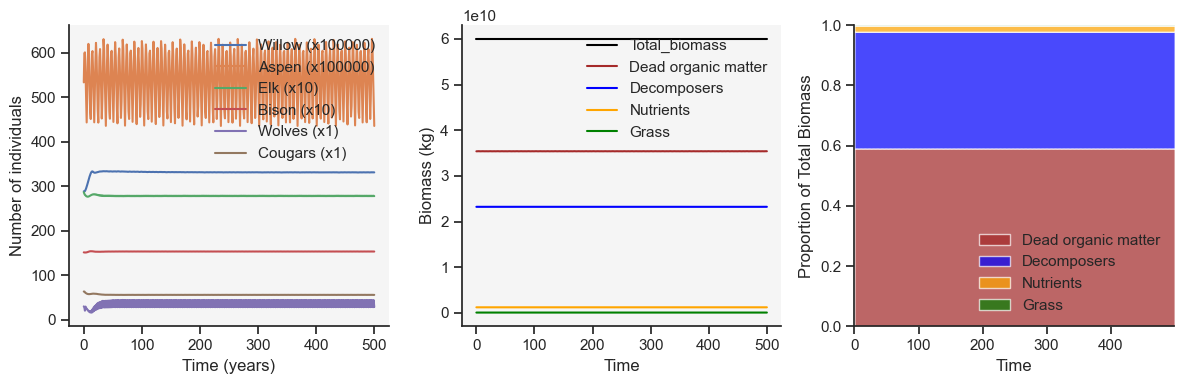

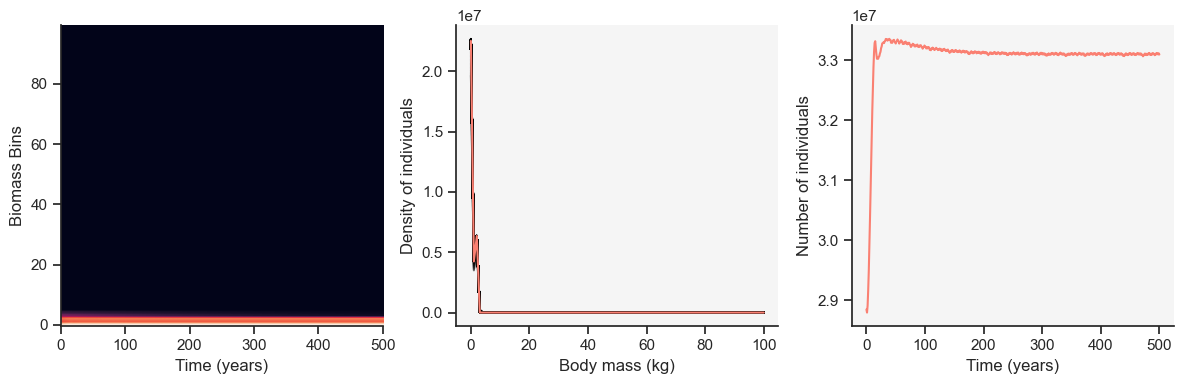

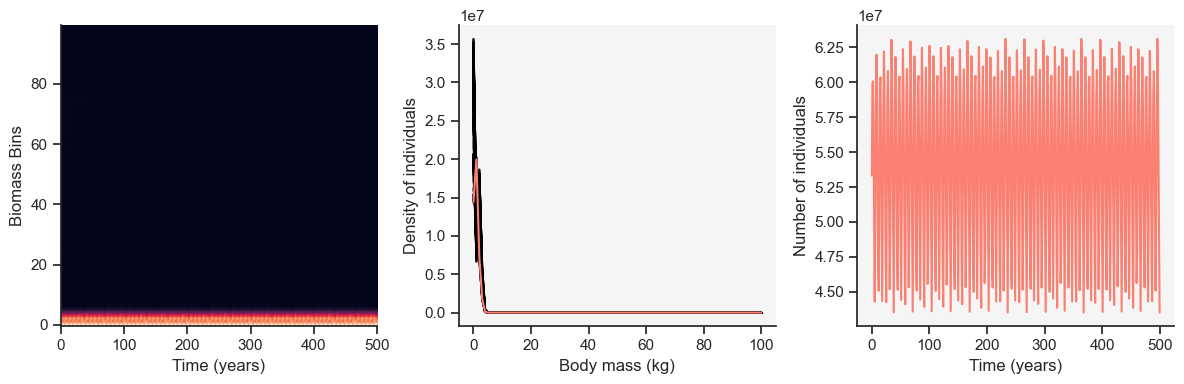

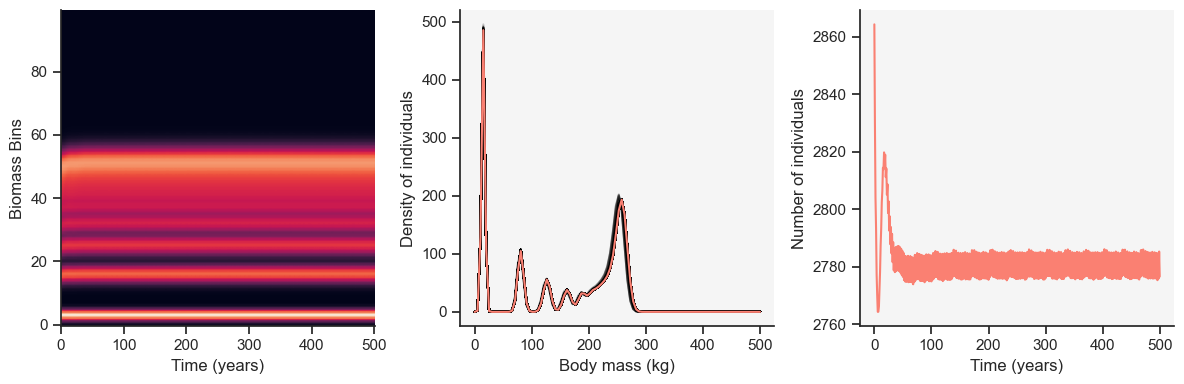

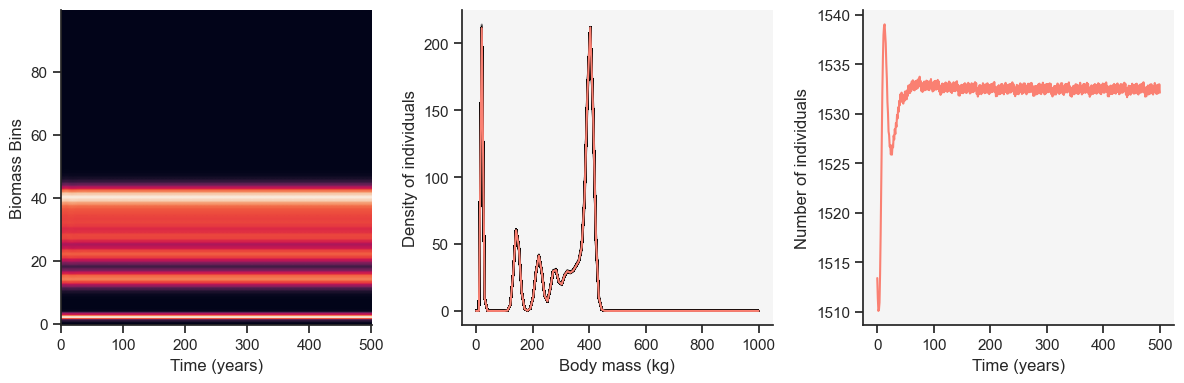

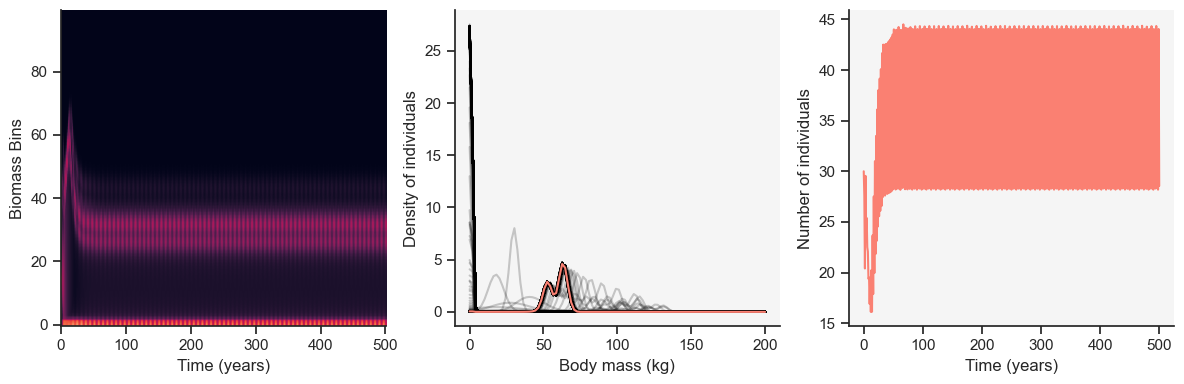

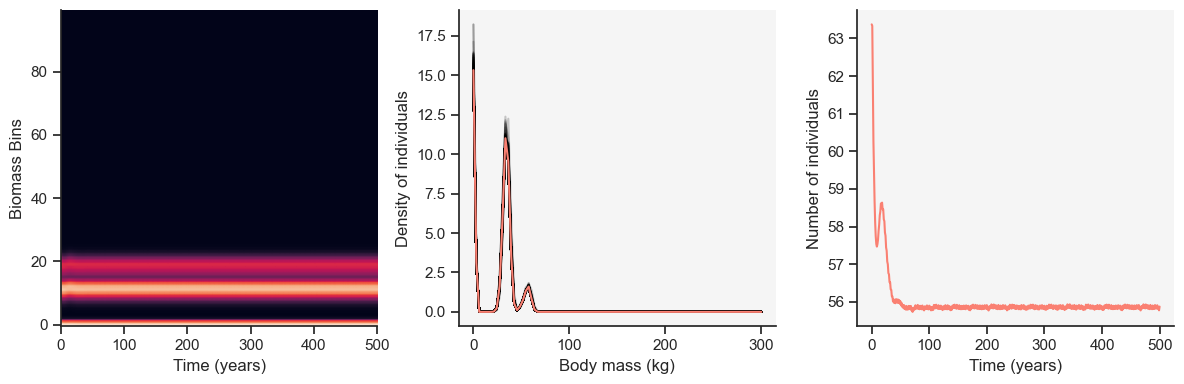

In [3]:
###############
## RUN MODEL ##
###############

## Initiate parameters
t_max = 500

## Period 1
t0 = time.time()
predictions = model.simulate(t_max=t_max,
                             Dt = Dt0,
                             Bt = Bt0,
                             Pt = Pt0,
                             Gt = Gt0,
                             NNt = NNt0,
                             NNNzt = NNNzt0,
                             zzmax = zzmax,
                             zzz_len = zzz_len
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions
tf = time.time()
print(f"{tf-t0:.2f}s")

## Visualise
plot_model(predictions)

#
###

In [4]:
#########################################
## FUNCTIONS ANALYSIS OF CHAIN RESULTS ##
#########################################

## Note: To convert to an import as shared between C1 and C2.

def get_map(chain):
    """
    """
    idx = torch.argmax(chain[:,0])
    ttheta_map = chain[idx,1:]
    return ttheta_map
     
#
###

In [5]:
################
## LOAD CHAIN ##
################

## Load
k = 29
sigma = 1.0
date = '2026-08-10'
run_id = f"C4-outputs/C4-real-map-sigma-{sigma}-{date}"
chain = torch.load(f"{run_id}-{k+1}-chain.pt")
cchain = torch.load(f"{run_id}-{k+1}-cchain.pt")
lloss = torch.load(f"{run_id}-{k+1}-lloss.pt")
ttheta_map = get_map(chain)

#
###

/var/folders/tb/4hh90ttd1nl4xf1zbfyq_n8w0000gp/T/ipykernel_80127/258955311.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chain = torch.load(f"{run_id}-{k+1}-chain.pt"

In [6]:
############################
## LOAD AND APPLY WRAPPER ##
############################

## Note: global variables should be in capital letters

## Import module
from f_wrapper_YEM_V1_14_2025_10_10 import wrapper_YEM_V1_14
from f_wrapper_YEM_V1_14_2025_10_10 import build_ttheta_index_map, get_name_from_index, get_index_from_name

## Model
model_r = YellowstoneEcosystemModel("parameters-apriori-V1-14-2025-10-10.yaml")
model_p = YellowstoneEcosystemModel("parameters-apriori-V1-14-2025-10-10.yaml")

## Define local wrapper
def wrapper(ttheta, t_max=30):
    return wrapper_YEM_V1_14(ttheta, t_max=t_max, model_r=model_r, model_p=model_p, Dt0=Dt0, Bt0=Bt0, Pt0=Pt0, Gt0=Gt0, NNt0=NNt0, NNNzt0=NNNzt0, zzmax=zzmax, zzz_len=zzz_len)

## Apply wrapper
predictions_map = wrapper(ttheta_map, t_max=10)

#
###

3.88s


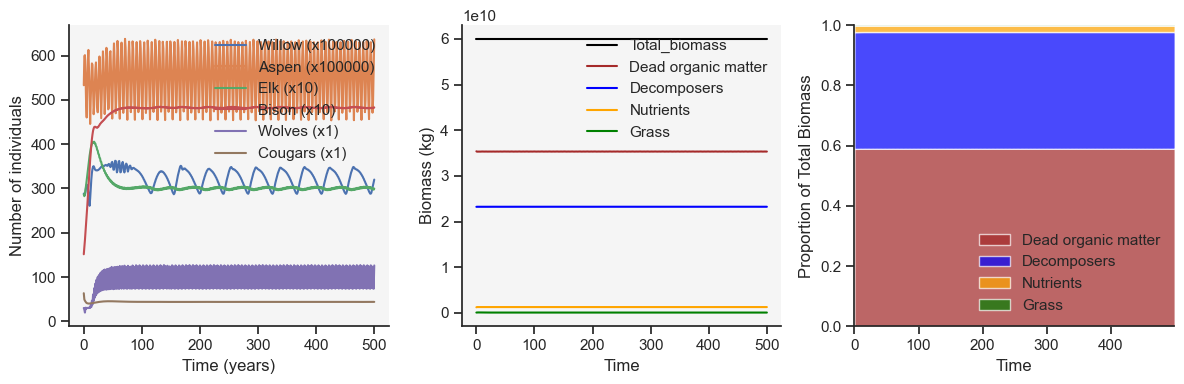

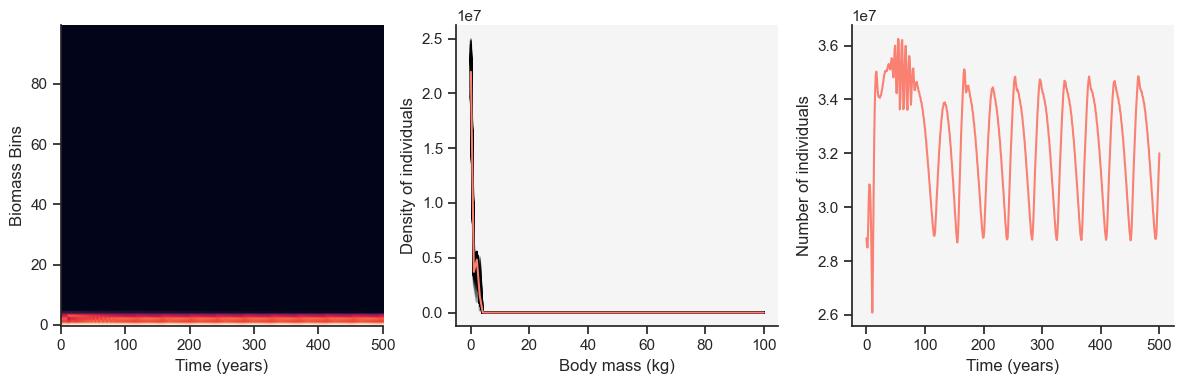

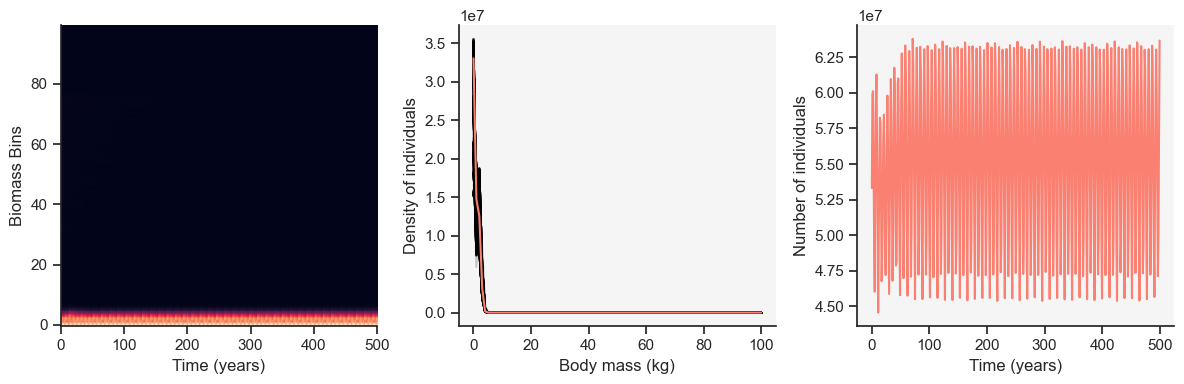

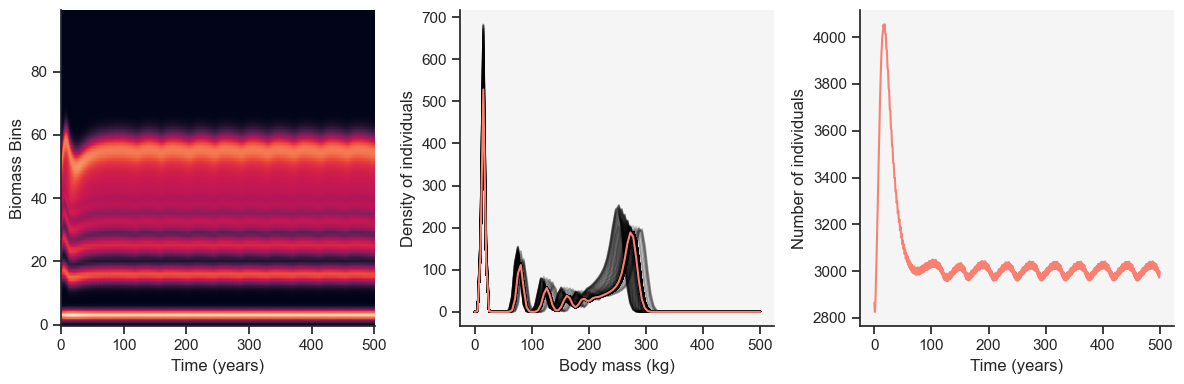

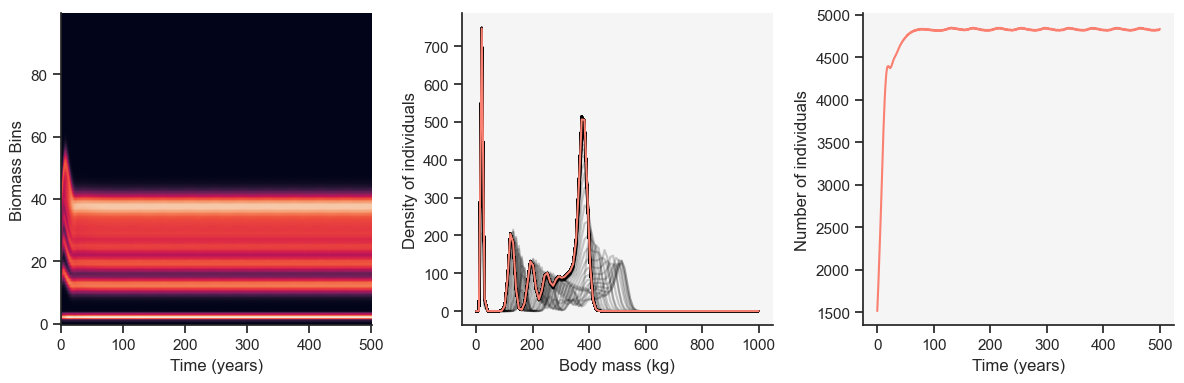

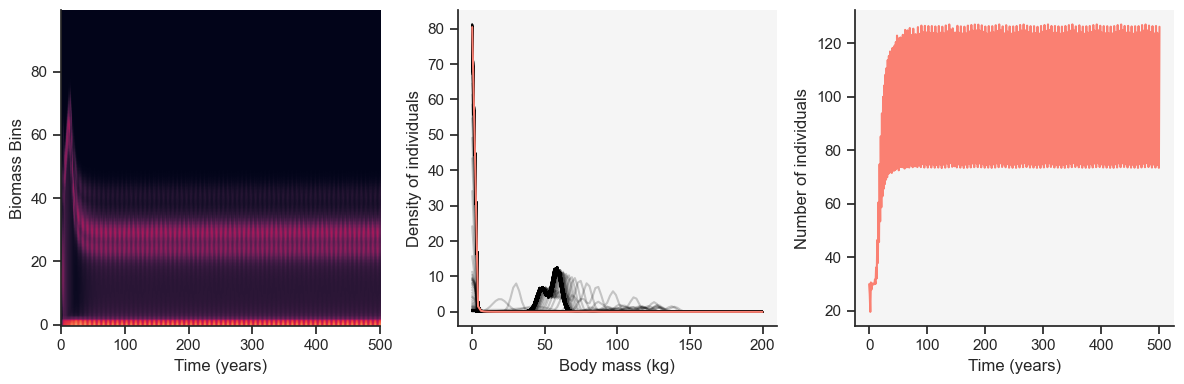

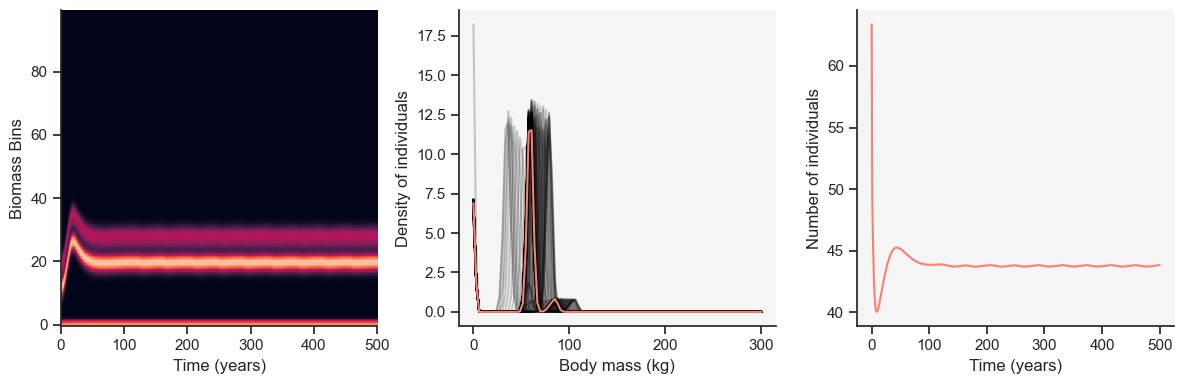

In [7]:
###############
## RUN MODEL ##
###############

## Initiate parameters
t_max = 500

## Period 1
t0 = time.time()
predictions = model_p.simulate(t_max=t_max,
                             Dt = Dt0,
                             Bt = Bt0,
                             Pt = Pt0,
                             Gt = Gt0,
                             NNt = NNt0,
                             NNNzt = NNNzt0,
                             zzmax = zzmax,
                             zzz_len = zzz_len
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions
tf = time.time()
print(f"{tf-t0:.2f}s")

## Visualise
plot_model(predictions)

#
###

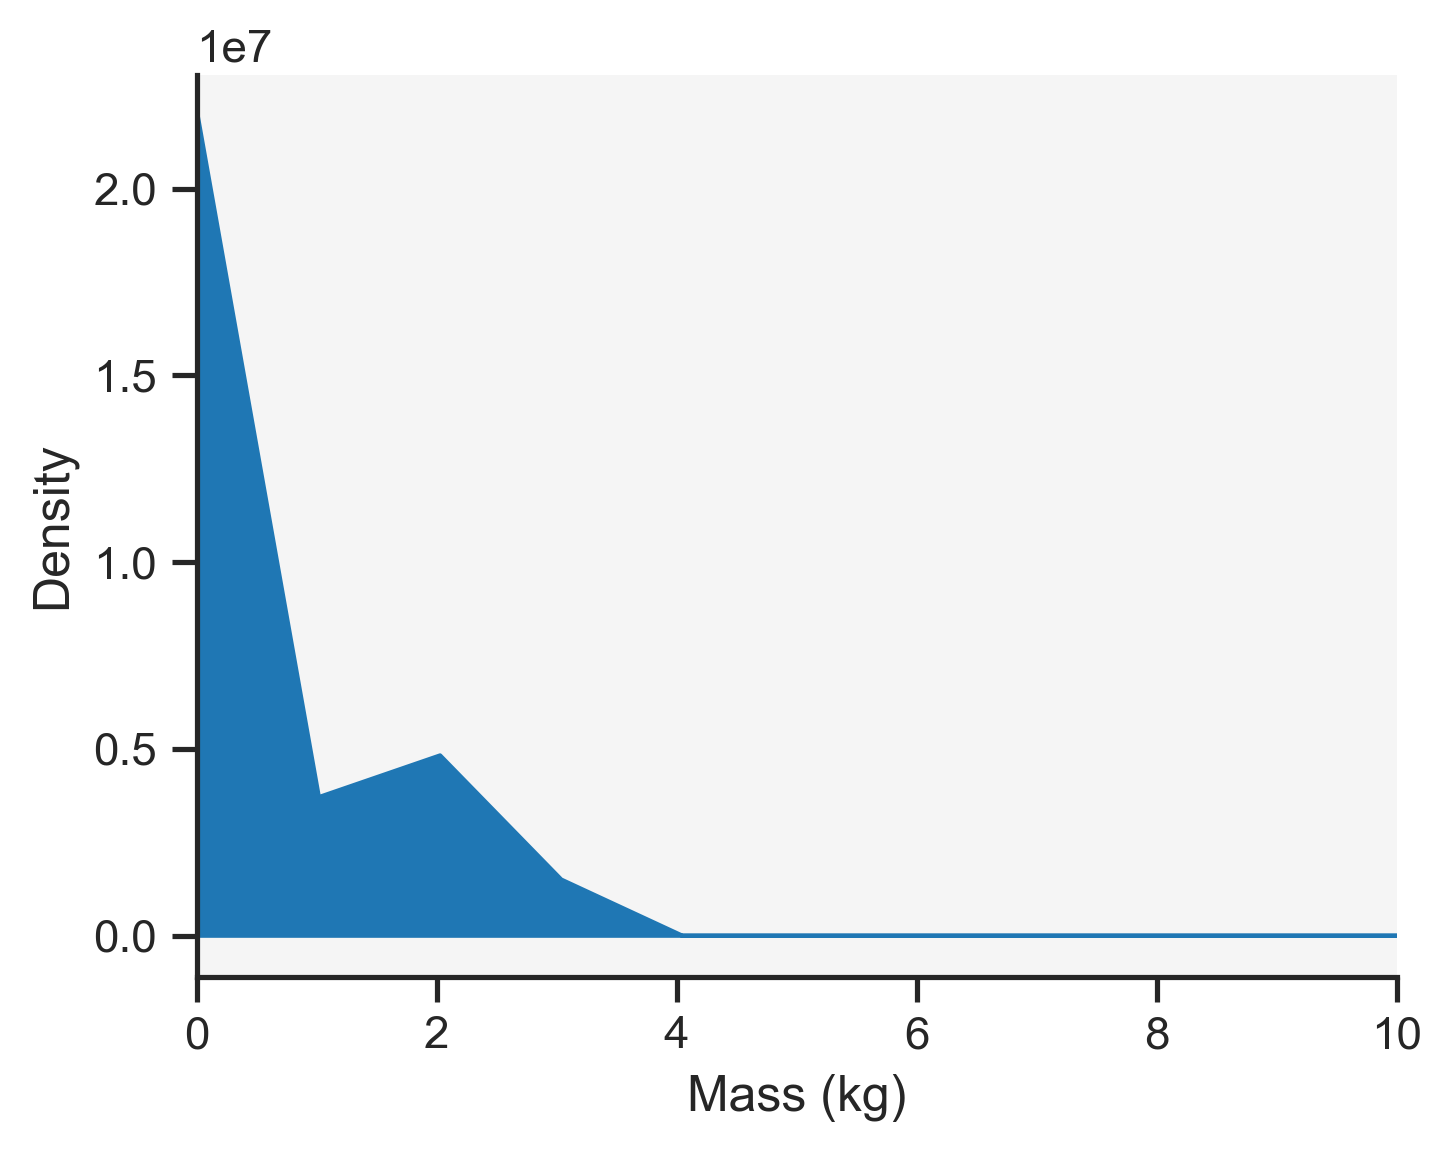

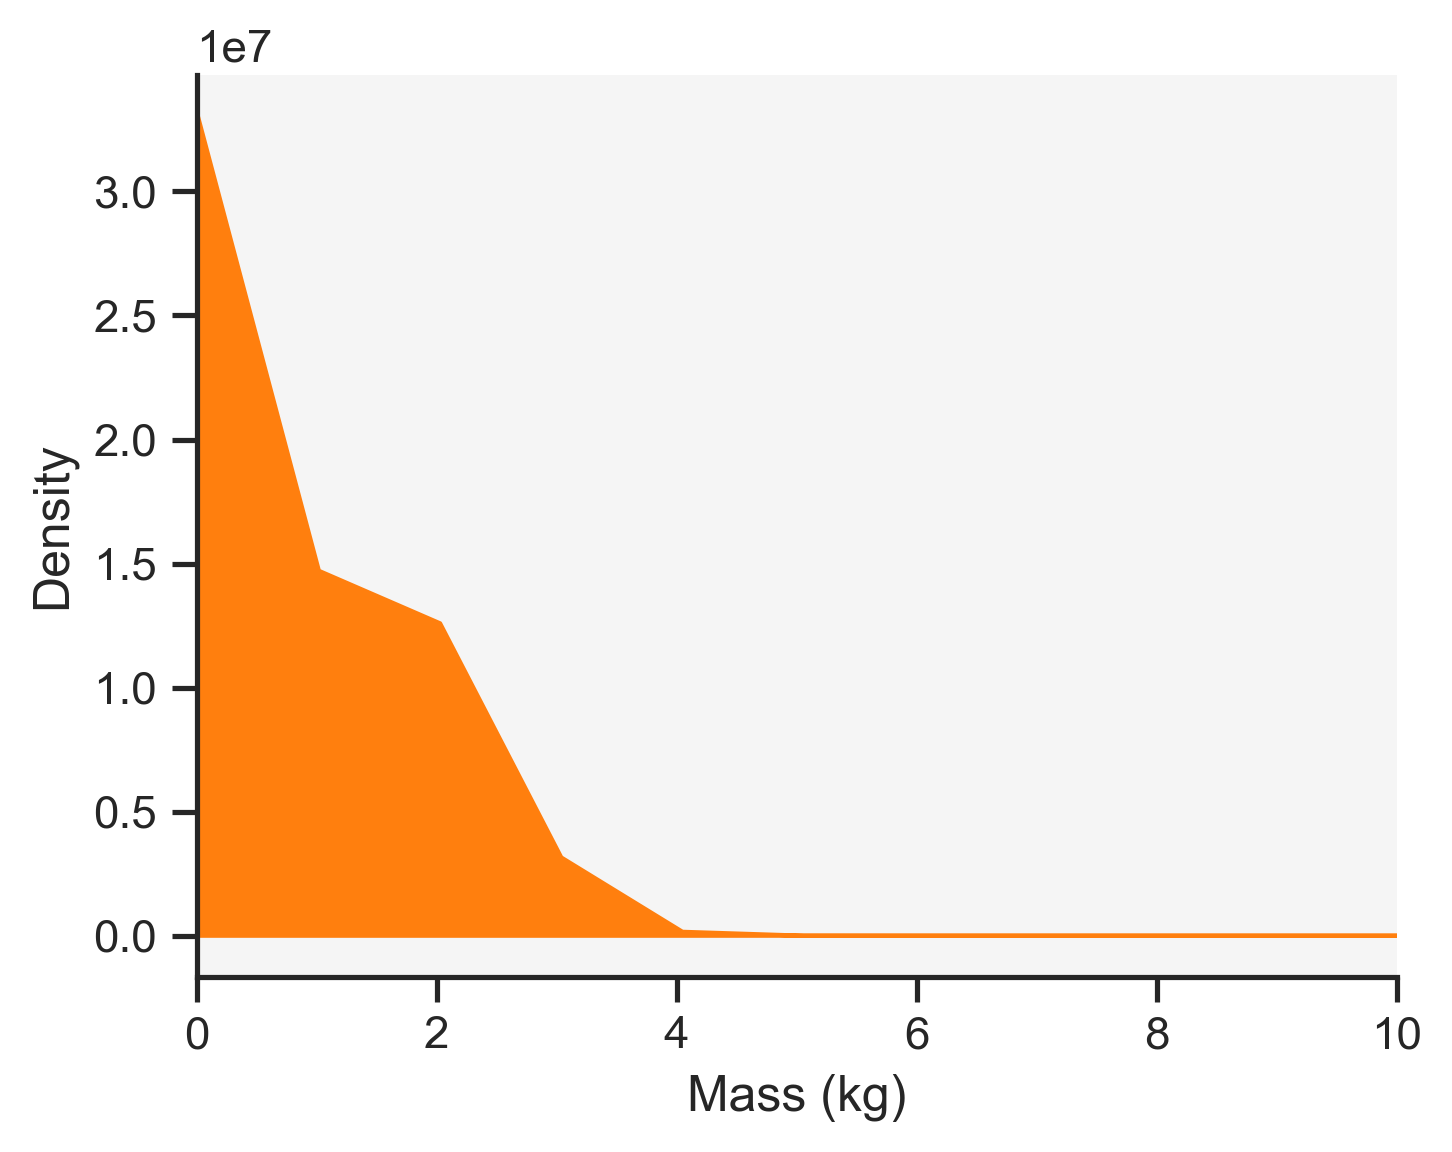

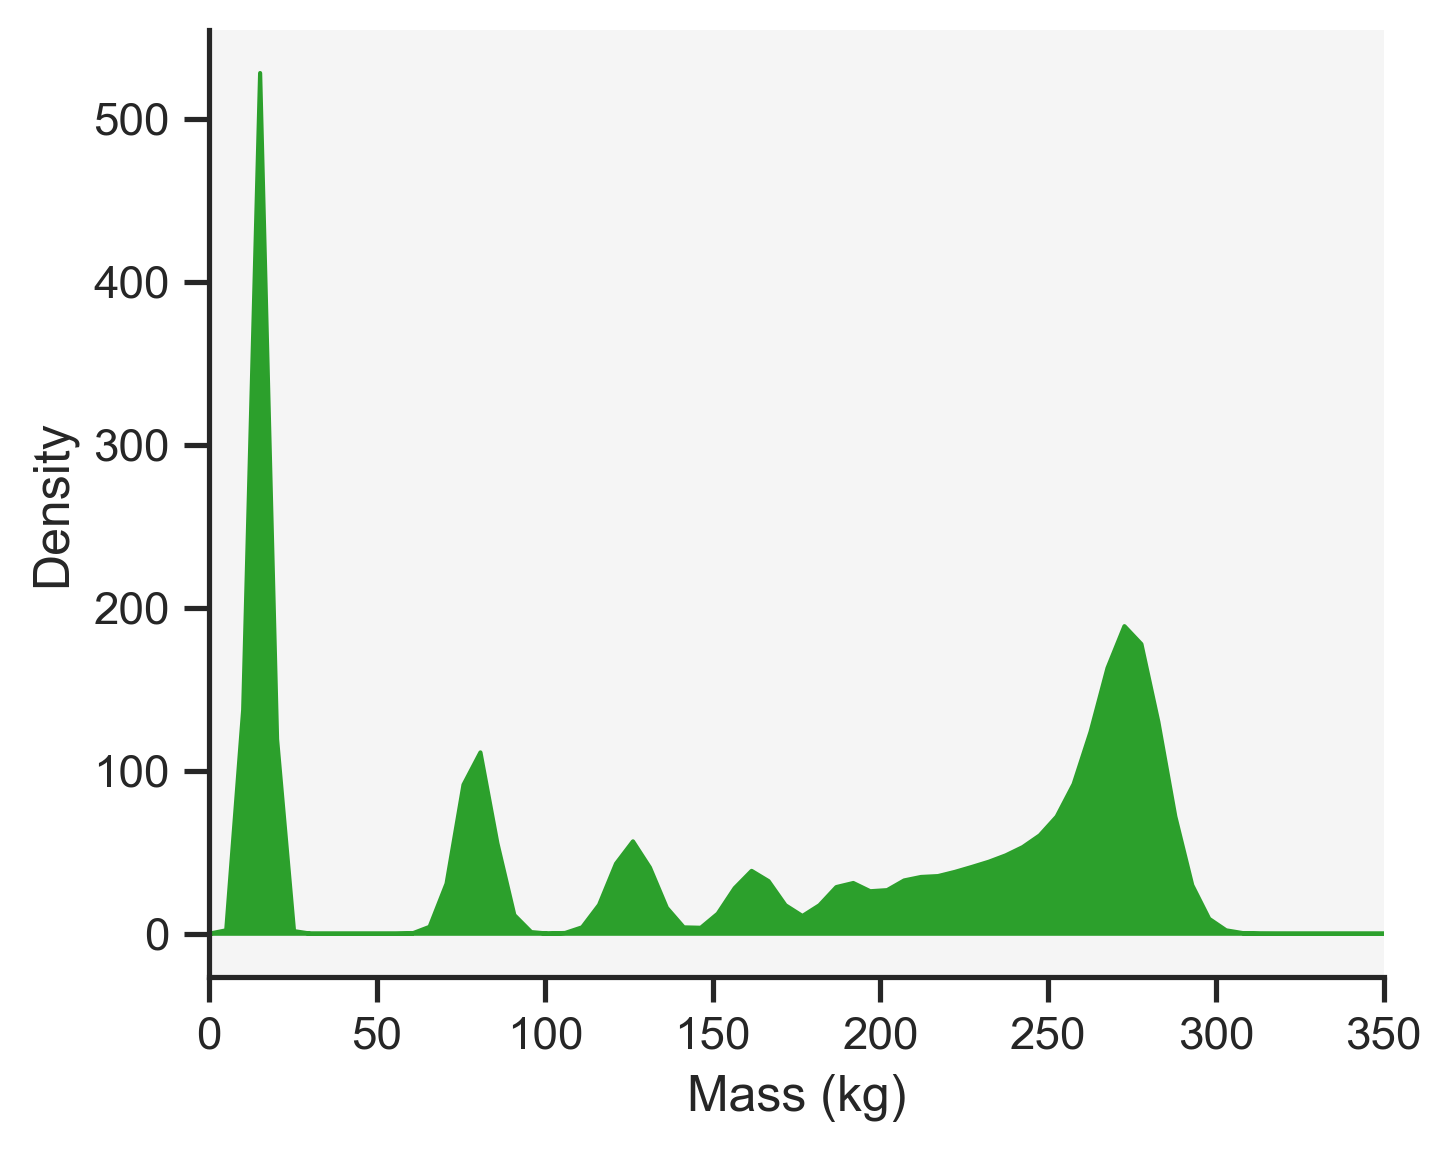

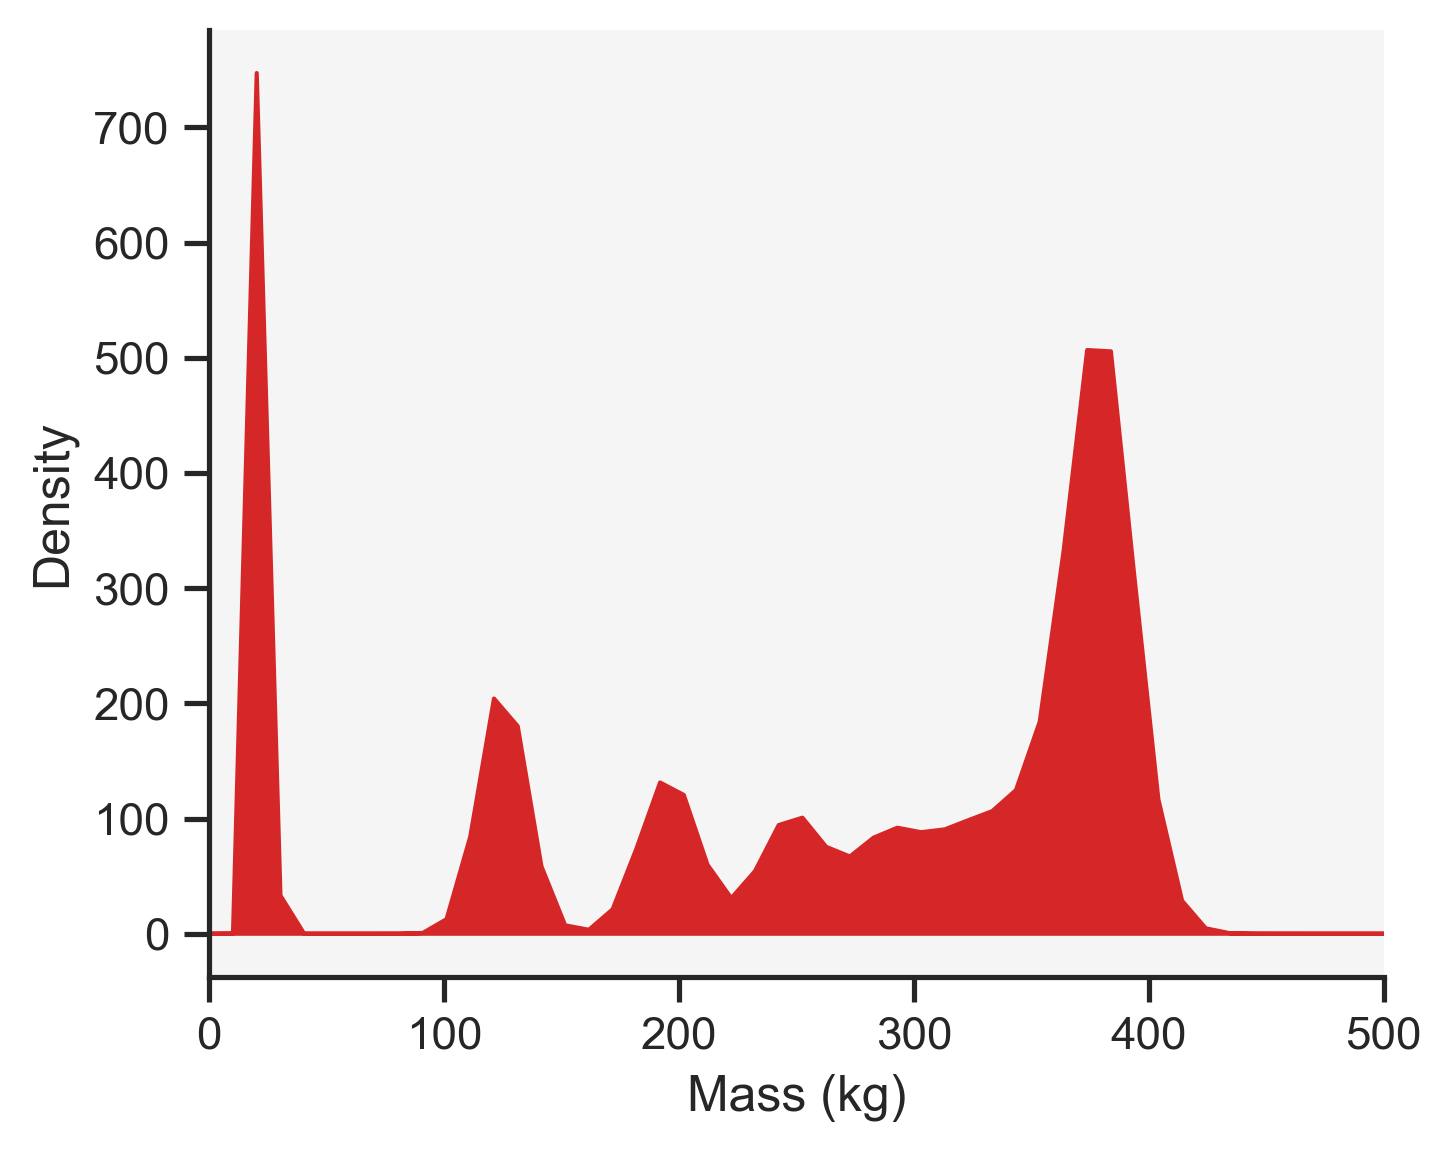

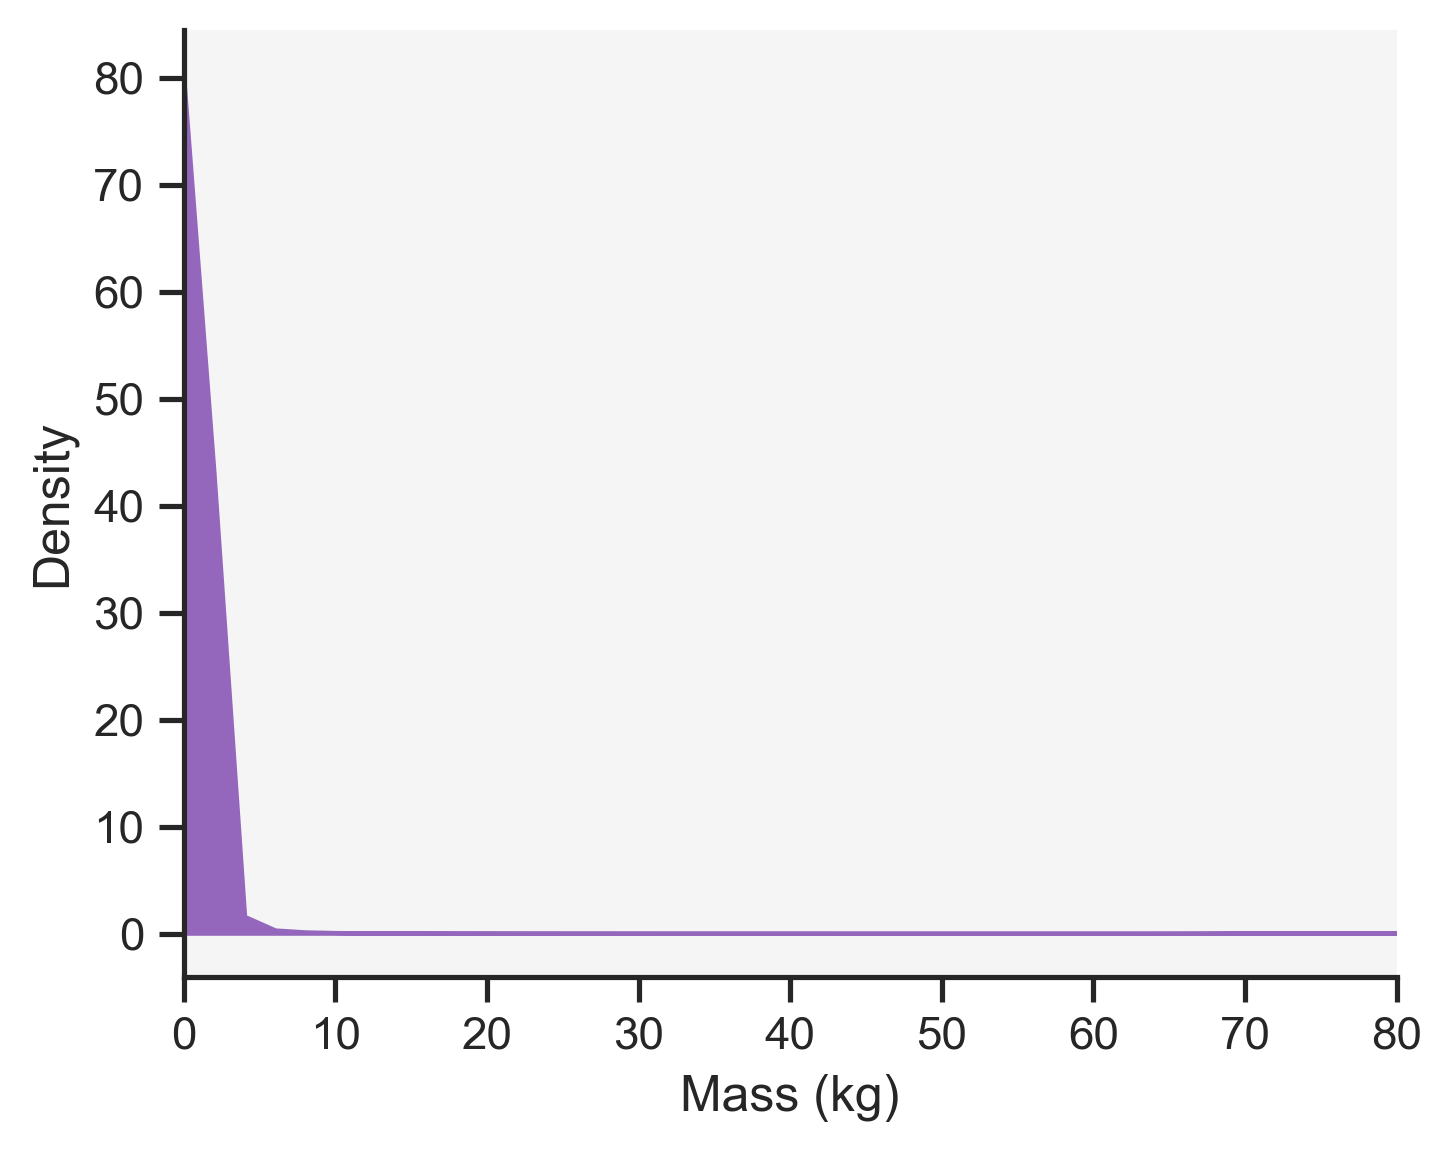

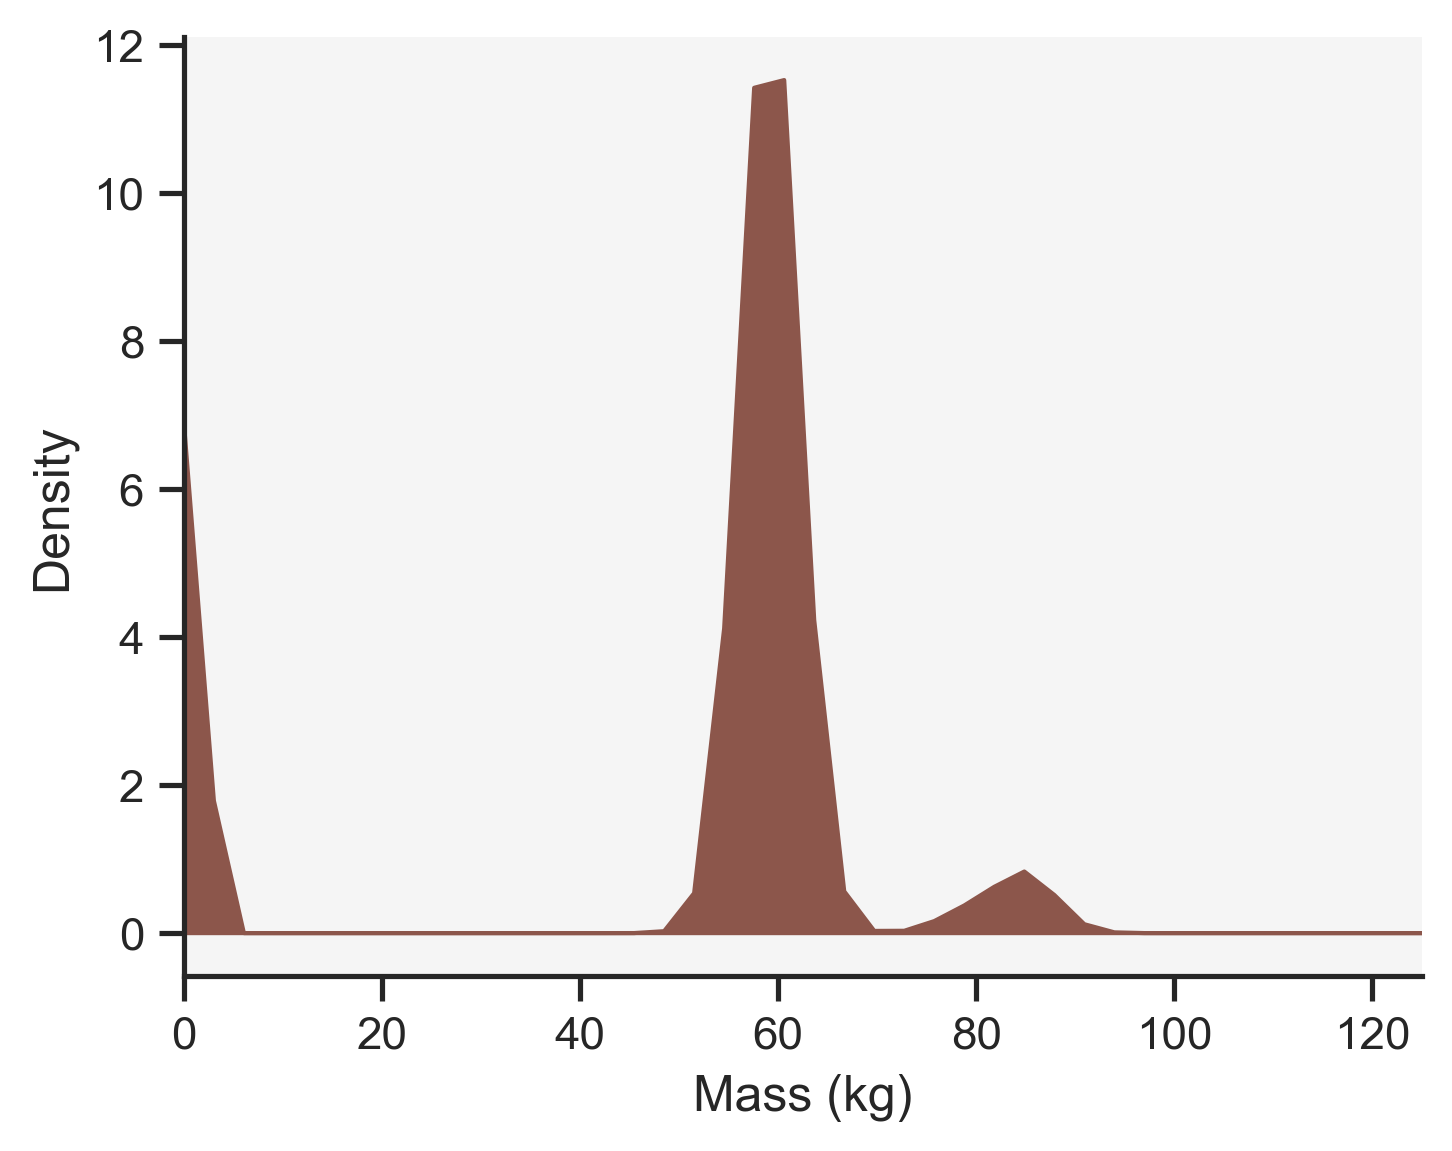

In [8]:
##############################
## CHECK MASS DISTRIBUTIONS ##
##############################

## Format output
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions

## Format
NNNNzt_new = [] # (time, species, phenotype) --> (species, time, phenotype)
for i in range(6):
    NNNzt_new = []
    for NNNzt in NNNNzt:
        NNNzt_new += [NNNzt[i].clone()]
    NNNNzt_new += [torch.stack(NNNzt_new)]
NNNNzt = torch.stack(NNNNzt_new)

## Global variables
SAVE = SAVEFIGS
FIGRES = 300
FIGSIZE = (5,4)

##
plt.rcParams['figure.dpi'] = FIGRES

"""
## Figure
for i in range(6):
    plt.figure(figsize=FIGSIZE)
    # plt.bar(zzz[i], NNNNzt[i,-1], facecolor='black', edgecolor='black')
    plt.plot(zzz[i], NNNNzt[i,-1], lw=1.0, color="black")
    plt.xlabel("Body Mass (kg)")
    plt.ylabel("Density")
    plt.show()
"""

colors = ["tab:blue", "tab:orange", "tab:green",
          "tab:red", "tab:purple", "tab:brown"]
xlims = [10, 10, 350, 500, 80, 125]

for i in range(6):
    plt.figure(figsize=FIGSIZE)

    plt.fill_between(
        zzz[i],
        NNNNzt[i, -1],
        color=colors[i],
        alpha=1.0
    )
    # plt.plot(zzz[i], NNNNzt[i, -1], color="black", lw=1.0)
    plt.xlim(0,xlims[i])
    plt.xlabel("Mass (kg)")
    plt.ylabel("Density")
    plt.tight_layout()
    if SAVE:
        plt.savefig(f"figures/{NBCODE}-calibrated-full-data-distribution-{i+1}.pdf")
    plt.show()

plt.rcParams['figure.dpi'] = 100

#
###

In [9]:
################################
## COMPUTE AVERGE MASS ADULTS ##
################################

z_maturity = [4, 4, 150, 400, 40, 35]
for i in range(6):
    zzbar_old = []
    for t in range(10):
        nnnnzt_ = (zzz[i] > z_maturity[i]) * NNNNzt[i,-t]
        nnnnzt_ = nnnnzt_ / nnnnzt_.sum()
        zzbar_old += [(zzz[i] * nnnnzt_).sum()]
    print(torch.tensor(zzbar_old).mean())

#
###

tensor(4.0500, dtype=torch.float64)
tensor(4.0592, dtype=torch.float64)
tensor(246.3601, dtype=torch.float64)
tensor(407.0801, dtype=torch.float64)
tensor(63.7940, dtype=torch.float64)
tensor(59.3862, dtype=torch.float64)


In [10]:
###############################
## ANALYSE PARAMETER SCALING ##
###############################

## Build index map
I = 6
J = 6
index_map = build_ttheta_index_map(I, J)

## Check
print("Index for bbeta_b0[3]:", get_index_from_name('bbeta_b0[3]', index_map))
print("Name for index 91:", get_name_from_index(91, index_map))

## Set threshold
th = 0.025
s_hi = np.sort(ttheta_map) > 1.0 + th
s_lo = np.sort(ttheta_map) < 1.0 - th
print(s_hi.sum())
print(s_lo.sum())

## Convert to list of strings
names = np.array([f"{get_name_from_index(i, index_map)}" for i in range(len(index_map))])

## Identify high and low scaling
th = 0.025
index_hi = np.where(ttheta_map > 1.0 + th)[0]
index_lo = np.where(ttheta_map < 1.0 - th)[0]
print(index_hi)
print(index_lo)

## Subset
s = np.concatenate((index_lo,index_hi))
names_subset = names[s]
ttheta_map_subset = ttheta_map[s]

## Sort
index_sorted = np.argsort(ttheta_map_subset)
ttheta_map_subset_sorted = ttheta_map_subset[index_sorted]
names_subset_sorted = names_subset[index_sorted]

#
###

Index for bbeta_b0[3]: 91
Name for index 91: bbeta_b0[3]
7
7
[ 13  15  17  74  88 106 123]
[ 82  92  96 109 113 120 122]


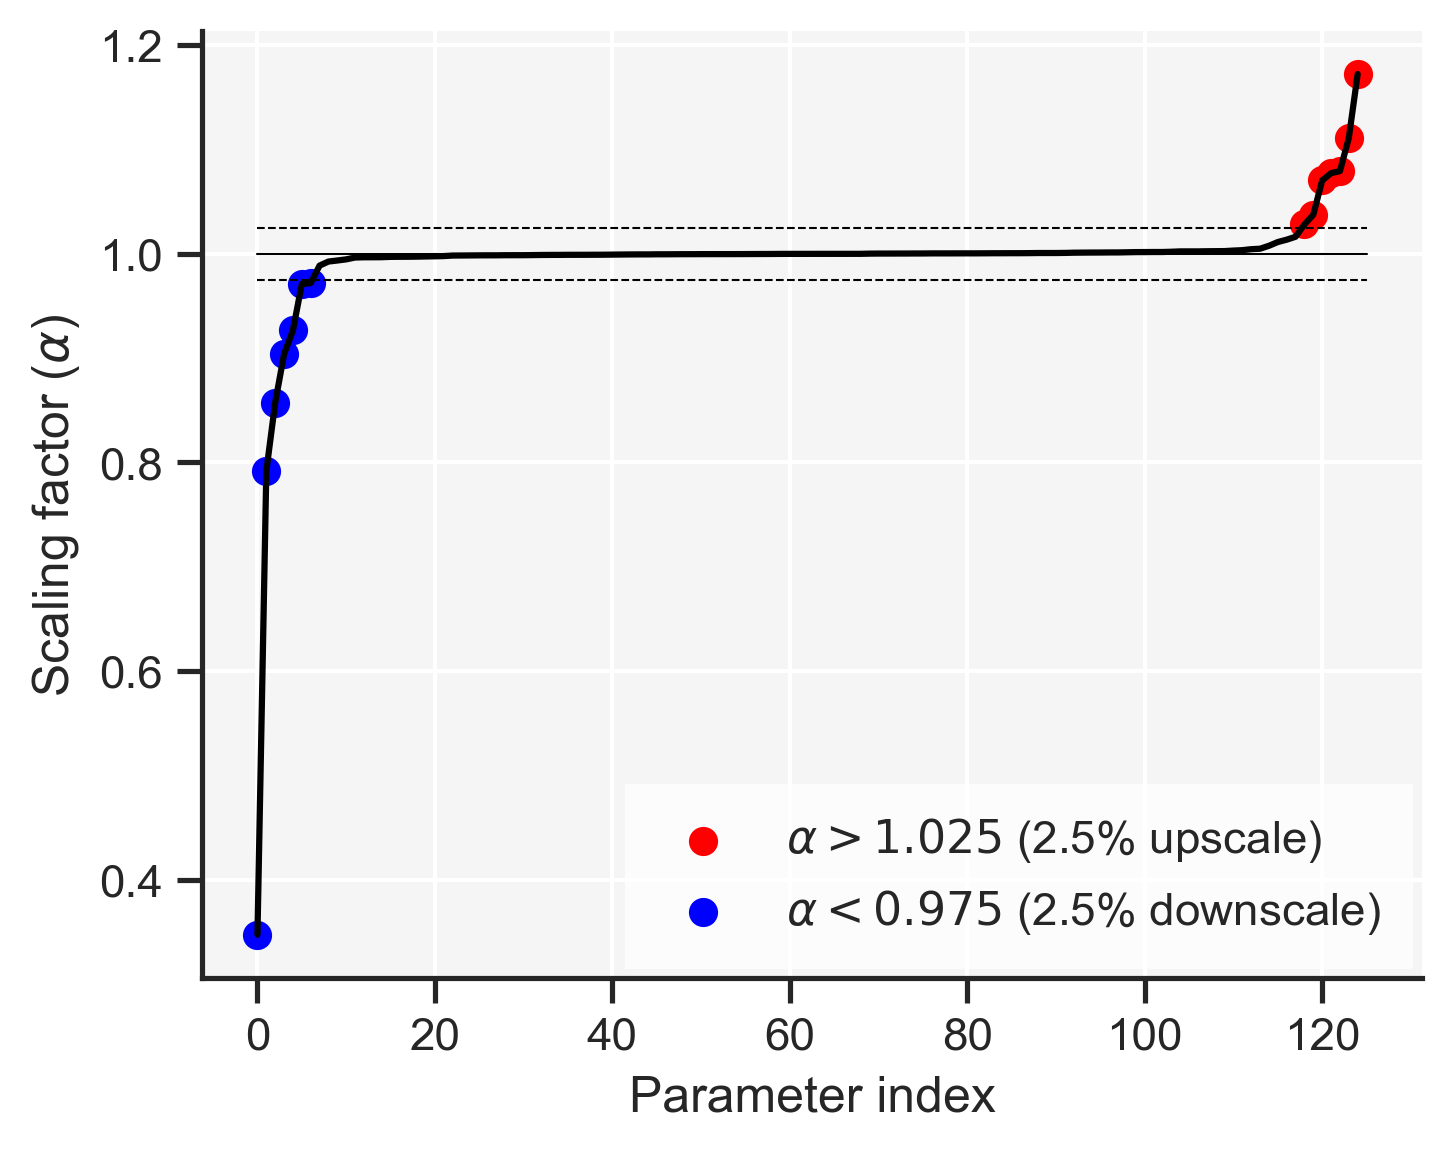

In [11]:
#####################################
## VISUALISE ALL PARAMETER SCALING ##
#####################################

## Global variables
SAVE = SAVEFIGS
FIGRES = 300
FIGSIZE = (5,4)

##
plt.rcParams['figure.dpi'] = FIGRES

## Figure
plt.figure(figsize=FIGSIZE)
#
plt.plot(range(0,len(ttheta_map)),np.sort(ttheta_map), color='black', lw=1.5)
plt.scatter(np.arange(0,len(ttheta_map))[s_hi],np.sort(ttheta_map)[s_hi],color='red', label=f"$\\alpha > 1.025$ (2.5% upscale)")
plt.scatter(np.arange(0,len(ttheta_map))[s_lo],np.sort(ttheta_map)[s_lo],color='blue', label=f"$\\alpha < 0.975$ (2.5% downscale)")
#
plt.plot([0,len(ttheta_map)],[1+th,1+th], '--', color='black', lw=0.5)
plt.plot([0,len(ttheta_map)],[1,1], '-', color='black', lw=0.5)
plt.plot([0,len(ttheta_map)],[1-th,1-th], '--', color='black', lw=0.5)
#
plt.xlabel('Parameter index')
plt.ylabel(f"Scaling factor ($\\alpha$)")
#
# plt.legend(frameon=False, fontsize=11)
leg = plt.legend(loc='lower right', ncol=1, fontsize=11)
frame = leg.get_frame()
frame.set_boxstyle('square')
frame.set_facecolor('white')
frame.set_edgecolor('none')
# plt.title('c.', loc='right', fontweight='bold')
plt.grid(color='white')
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-calibrated-full-data-parameters.pdf")
plt.show()

##
plt.rcParams['figure.dpi'] = 100

#
###

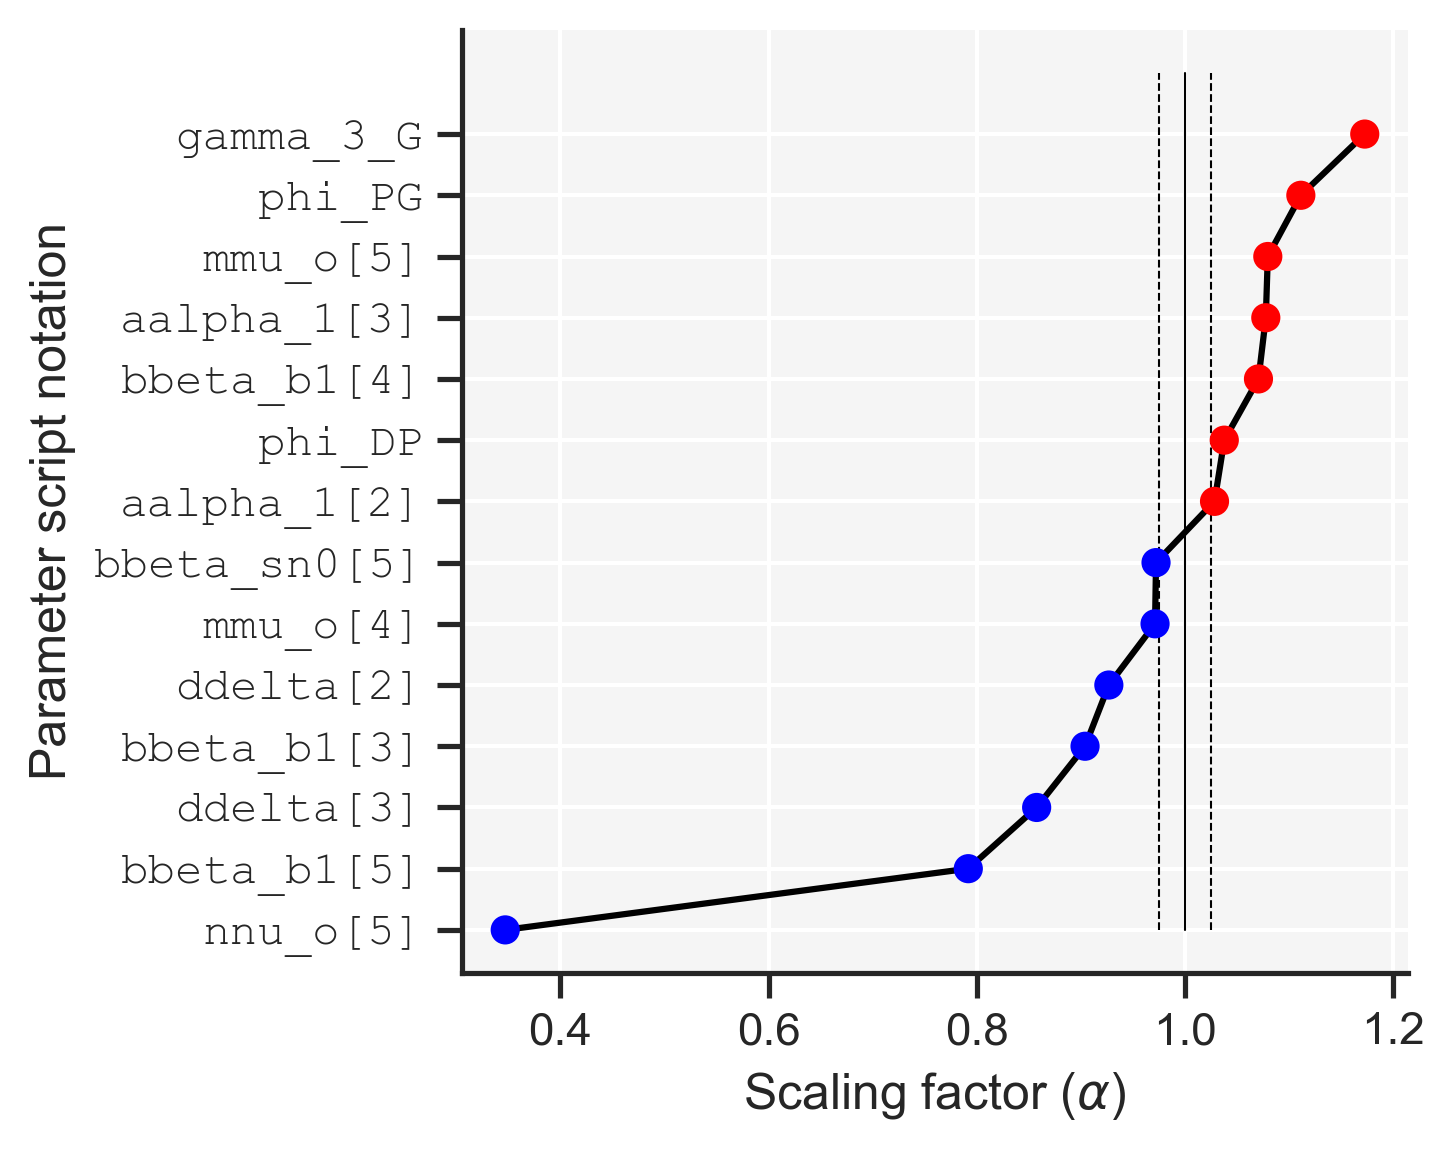

In [12]:
##############################################
## VISUALISE HIGH AND LOW PARAMETER SCALING ##
##############################################

## Global variables
SAVE = SAVEFIGS
FIGRES = 300
FIGSIZE = (5,4)

##
plt.rcParams['figure.dpi'] = FIGRES

## Figure
plt.figure(figsize=FIGSIZE)
#
plt.plot(ttheta_map_subset_sorted, np.arange(0, len(ttheta_map_subset_sorted)), color='black')
plt.scatter(ttheta_map_subset_sorted, np.arange(0, len(ttheta_map_subset_sorted)), c=ttheta_map_subset_sorted>1, cmap='bwr', zorder=3)
#
plt.plot([1+th,1+th], [0,len(ttheta_map_subset_sorted)],'--', color='black', lw=0.5)
plt.plot([1,1], [0,len(ttheta_map_subset_sorted)],'-', color='black', lw=0.5)
plt.plot([1-th,1-th], [0,len(ttheta_map_subset_sorted)],'--', color='black', lw=0.5)
#
plt.yticks(np.arange(0, len(names_subset_sorted)), names_subset_sorted)
plt.yticks(fontname="Courier New")
#
plt.xlabel(f"Scaling factor ($\\alpha$)")
plt.ylabel("Parameter script notation")
#
plt.grid(True, alpha=1.0, color='white')
# plt.title('d.', loc='right', fontweight='bold')
#
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-calibrated-full-data-parameters-compact.pdf")
plt.show()

##
plt.rcParams['figure.dpi'] = 100

#
###

In [28]:
###########################
## SAVE MODEL PARAMETERS ##
###########################

SAVE = False
if SAVE:
    
    ## Save parameters
    model_p.save_params('parameters-aposteriori-V1-14-2025-10-10-sigma-1.0-2026-08-10-29.yaml')
    
    ## Checks
    model_debug = YellowstoneEcosystemModel("parameters-aposteriori-V1-14-2025-10-10-sigma-1.0-2026-08-10-29.yaml")
    print(model_p.phi_BD.item())
    print(model_debug.phi_BD.item())
    print(model_p.phi_PG.item())
    print(model_debug.phi_PG.item())
    print(model_p.bbeta_sn0[0].item())
    print(model_debug.bbeta_sn0[0].item())

#
###

0.2501032100760986
0.2501032100760986
0.0032079380108258615
0.0032079380108258615
0.982935177790582
0.982935177790582


In [21]:
#################################
## MAKE SUMMARY TABLE (RUN 19) ##
#################################

print('')
print('hi')
for index_hi_ in index_hi:
    print(get_name_from_index(index_hi_, index_map))
    # name_ = get_name_from_index(index_hi_, index_map)
    # print(f"{name_} & {getattr(model_r, name_)}")
print('')
print('lo')
for index_lo_ in index_lo:
    print(get_name_from_index(index_lo_, index_map))

# --- High scaling ("hi") ---
print('')
print('hig')
print(f"phi_PG & {model_r.phi_PG:.4f} & {model_p.phi_PG:.4f} \\\\")
print(f"aalpha_1[3] & {model_r.aalpha_1[3]:.4f} & {model_p.aalpha_1[3]/model_r.aalpha_2[3]:.4f} \\\\")
print(f"gamma_3_G & {model_r.gamma_3_G:.4f} & {model_p.gamma_3_G:.4f} \\\\")
print(f"aalpha_1[2] & {model_r.aalpha_1[2]:.4f} & {model_p.aalpha_1[2]/model_r.aalpha_2[2]:.4f} \\\\")
print(f"bbeta_b1[4] & {model_r.bbeta_b1[4]:.4f} & {model_p.bbeta_b1[4]:.4f} \\\\")
print(f"mmu_o[5] & {model_r.mmu_o[5]:.4f} & {model_p.mmu_o[5]:.4f} \\\\")
print(f"nnu_o[4] & {model_r.nnu_o[4]:.4f} & {model_p.nnu_o[4]:.4f} \\\\")
print(f"bbbeta_dp2[4][4] & {model_r.bbbeta_dp2[4][4]:.4f} & {model_p.bbbeta_dp2[4][4]:.4f} \\\\")

# --- Low scaling ("lo") ---
print('')
print('lo')
print(f"ddelta[2] & {model_r.ddelta[2]:.4f} & {model_p.ddelta[2]:.4f} \\\\")
print(f"mmu_o[4] & {model_r.mmu_o[4]:.4f} & {model_p.mmu_o[4]:.4f} \\\\")
print(f"ddelta[3] & {model_r.ddelta[3]:.4f} & {model_p.ddelta[3]:.4f} \\\\")
print(f"nnu_o[5] & {model_r.nnu_o[5]:.4f} & {model_p.nnu_o[5]:.4f} \\\\")
print(f"bbeta_b1[5] & {model_r.bbeta_b1[5]:.4f} & {model_p.bbeta_b1[5]:.4f} \\\\")


#
###


hi
phi_PG
gamma_3_G
bbbeta_dp2[4][4]
aalpha_1[2]
aalpha_1[3]
bbeta_b1[4]
nnu_o[4]
mmu_o[5]

lo
ddelta[2]
ddelta[3]
mmu_o[4]
bbeta_b1[5]
nnu_o[5]

hig
phi_PG & 0.0032 & 0.0037 \\
aalpha_1[3] & 0.6200 & 0.7064 \\
gamma_3_G & 13.3300 & 15.0948 \\
aalpha_1[2] & 0.5700 & 0.6095 \\
bbeta_b1[4] & 40.0000 & 41.8848 \\
mmu_o[5] & 1.0000 & 1.0441 \\
nnu_o[4] & 0.0590 & 0.0612 \\
bbbeta_dp2[4][4] & -0.1000 & -0.1031 \\

lo
ddelta[2] & 1.0000 & 0.9690 \\
mmu_o[4] & 1.0000 & 0.9668 \\
ddelta[3] & 1.4225 & 1.2545 \\
nnu_o[5] & 0.0700 & 0.0588 \\
bbeta_b1[5] & 35.0000 & 10.7702 \\


In [22]:
#############################
## COMPARE EACH PARAMETERS ##
#############################

import torch
import numpy as np

def format_tensor(tensor, precision=4, scientific=False):
    """Detach, convert, and format a PyTorch tensor."""
    if torch.is_tensor(tensor):
        tensor = tensor.detach().cpu().numpy()
    if isinstance(tensor, (list, tuple, np.ndarray)):
        fmt = f"{{:.{precision}e}}" if scientific else f"{{:.{precision}f}}"
        return "[" + ", ".join(fmt.format(x) for x in tensor) + "]"
    else:
        fmt = f"{{:.{precision}e}}" if scientific else f"{{:.{precision}f}}"
        return fmt.format(tensor)

def print_parameter_comparison(name, val_r, val_p, indent=2, precision=4, scientific=False):
    pad = ' ' * indent
    print(f"{name}:")
    print(f"{pad}model_r: {format_tensor(val_r, precision, scientific)}")
    print(f"{pad}model_p: {format_tensor(val_p, precision, scientific)}")
    print("")

print("\n====================")
print("== ECOSYSTEM ==")
print("====================")
print(f"phi_BD: {model_r.phi_BD:.4f} {model_p.phi_BD:.4f}")
print(f"phi_DB: {model_r.phi_DB:.4f} {model_p.phi_DB:.4f}")
print(f"rho_B: {model_r.rho_B:.4f} {model_p.rho_B:.4f}")
print(f"phi_DP: {model_r.phi_DP:.4f} {model_p.phi_DP:.4f}")
print(f"phi_GD: {model_r.phi_GD:.4f} {model_p.phi_GD:.4f}")
print(f"phi_PG: {model_r.phi_PG:.4f} {model_p.phi_PG:.4f}")
print(f"rho_G: {model_r.rho_G:.4f} {model_p.rho_G:.4f}")
print(f"gamma_3_G: {model_r.gamma_3_G:.4f} {model_p.gamma_3_G:.4f}")

print("====================")
print("== NUTRIENTS & HERBIVORY ==")
print("====================")
print_parameter_comparison("bbeta_dh0_P", model_r.bbeta_dh0_P, model_p.bbeta_dh0_P)
print_parameter_comparison("bbeta_dh0_G", model_r.bbeta_dh0_G, model_p.bbeta_dh0_G)

print("====================")
print("== PREDATION ==")
for i in range(6):
    print(f"-- Species {i+1} --")
    print_parameter_comparison(f"bbbeta_dp0[{i}]", model_r.bbbeta_dp0[i], model_p.bbbeta_dp0[i])
    print_parameter_comparison(f"bbbeta_dp1[{i}]", model_r.bbbeta_dp1[i], model_p.bbbeta_dp1[i])
    print_parameter_comparison(f"bbbeta_dp2[{i}]", model_r.bbbeta_dp2[i], model_p.bbbeta_dp2[i])

print("====================")
print("== SCAVENGING ==")
for i in range(6):
    print(f"-- Species {i+1} --")
    print_parameter_comparison(f"lllambda[{i}]", model_r.lllambda[i], model_p.lllambda[i])
    # print_parameter_comparison(f"bbbeta_dn0[{i}]", model_r.bbbeta_dn0[i], model_p.bbbeta_dn0[i])

print("====================")
print("== SURVIVAL ==")
print_parameter_comparison("bbeta_sn0", model_r.bbeta_sn0, model_p.bbeta_sn0)
print_parameter_comparison("bbeta_sn1", model_r.bbeta_sn1, model_p.bbeta_sn1)
print_parameter_comparison("bbeta_sn2", model_r.bbeta_sn2, model_p.bbeta_sn2)

print("====================")
print("== REPRODUCTION ==")
print_parameter_comparison("bbeta_b0", model_r.bbeta_b0, model_p.bbeta_b0)
print_parameter_comparison("bbeta_b1", model_r.bbeta_b1, model_p.bbeta_b1)
print_parameter_comparison("bbeta_b2", model_r.bbeta_b2, model_p.bbeta_b2)
print_parameter_comparison("nnu_o", model_r.nnu_o, model_p.nnu_o)
print_parameter_comparison("mmu_o", model_r.mmu_o, model_p.mmu_o)

print("====================")
print("== ASSIMILATION ==")
print_parameter_comparison("aalpha_1", model_r.aalpha_1, model_p.aalpha_1)
print_parameter_comparison("aalpha_2", model_r.aalpha_2, model_p.aalpha_2)

print("====================")
print("== CONSUMPTION ==")
print_parameter_comparison("ggamma_1", model_r.ggamma_1, model_p.ggamma_1)
print_parameter_comparison("ggamma_2", model_r.ggamma_2, model_p.ggamma_2)

print("====================")
print("== MAINTENANCE ==")
print_parameter_comparison("ddelta", model_r.ddelta, model_p.ddelta)

#
##


== ECOSYSTEM ==
phi_BD: 0.2500 0.2501
phi_DB: 0.2000 0.2004
rho_B: 54.7500 54.8025
phi_DP: 0.1750 0.1763
phi_GD: 0.0330 0.0330
phi_PG: 0.0032 0.0037
rho_G: 1.3046 1.3060
gamma_3_G: 13.3300 15.0948
== NUTRIENTS & HERBIVORY ==
bbeta_dh0_P:
  model_r: [0.0029, 0.0002, 0.0000, 0.0000, 0.0000, 0.0000]
  model_p: [0.0029, 0.0002, 0.0000, 0.0000, 0.0000, 0.0000]

bbeta_dh0_G:
  model_r: [0.0000, 0.0000, 0.0002, 0.0003, 0.0000, 0.0000]
  model_p: [0.0000, 0.0000, 0.0002, 0.0003, 0.0000, 0.0000]

== PREDATION ==
-- Species 1 --
bbbeta_dp0[0]:
  model_r: [0.0000, 0.0000, 0.0003, 0.0000, 0.0000, 0.0000]
  model_p: [0.0000, 0.0000, 0.0003, 0.0000, 0.0000, 0.0000]

bbbeta_dp1[0]:
  model_r: [0.0000, 0.0000, 2.0000, 0.0000, 0.0000, 0.0000]
  model_p: [0.0000, 0.0000, 1.9932, 0.0000, 0.0000, 0.0000]

bbbeta_dp2[0]:
  model_r: [0.0000, 0.0000, -10.0000, 0.0000, 0.0000, 0.0000]
  model_p: [0.0000, 0.0000, -10.0128, 0.0000, 0.0000, 0.0000]

-- Species 2 --
bbbeta_dp0[1]:
  model_r: [0.0000, 0.0000, 0.0

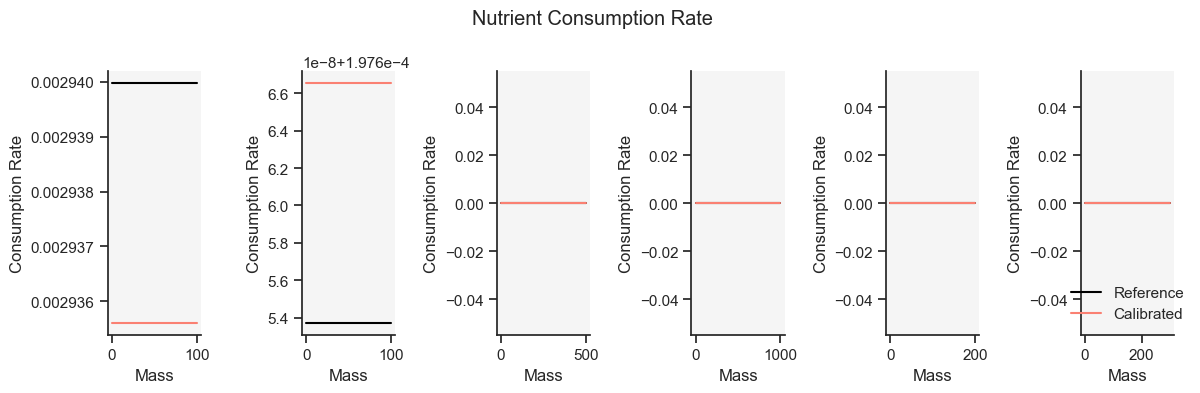

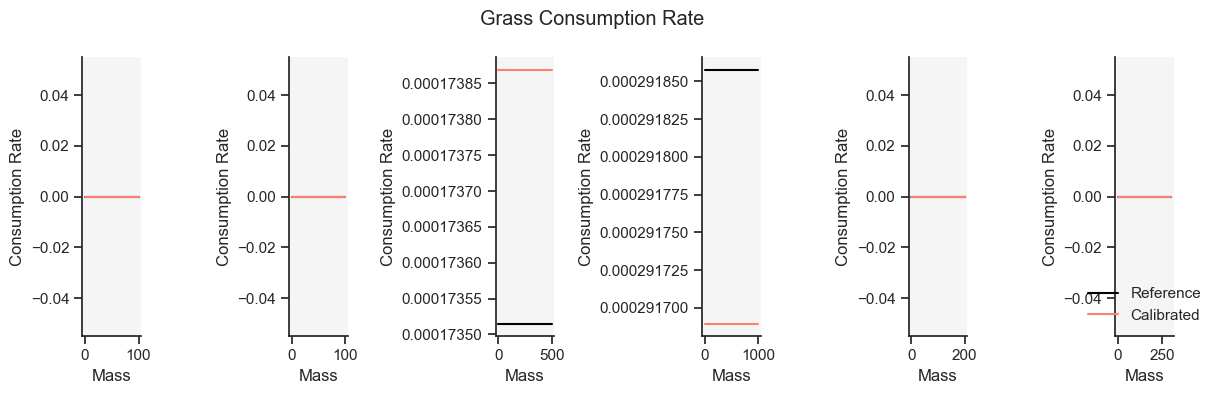

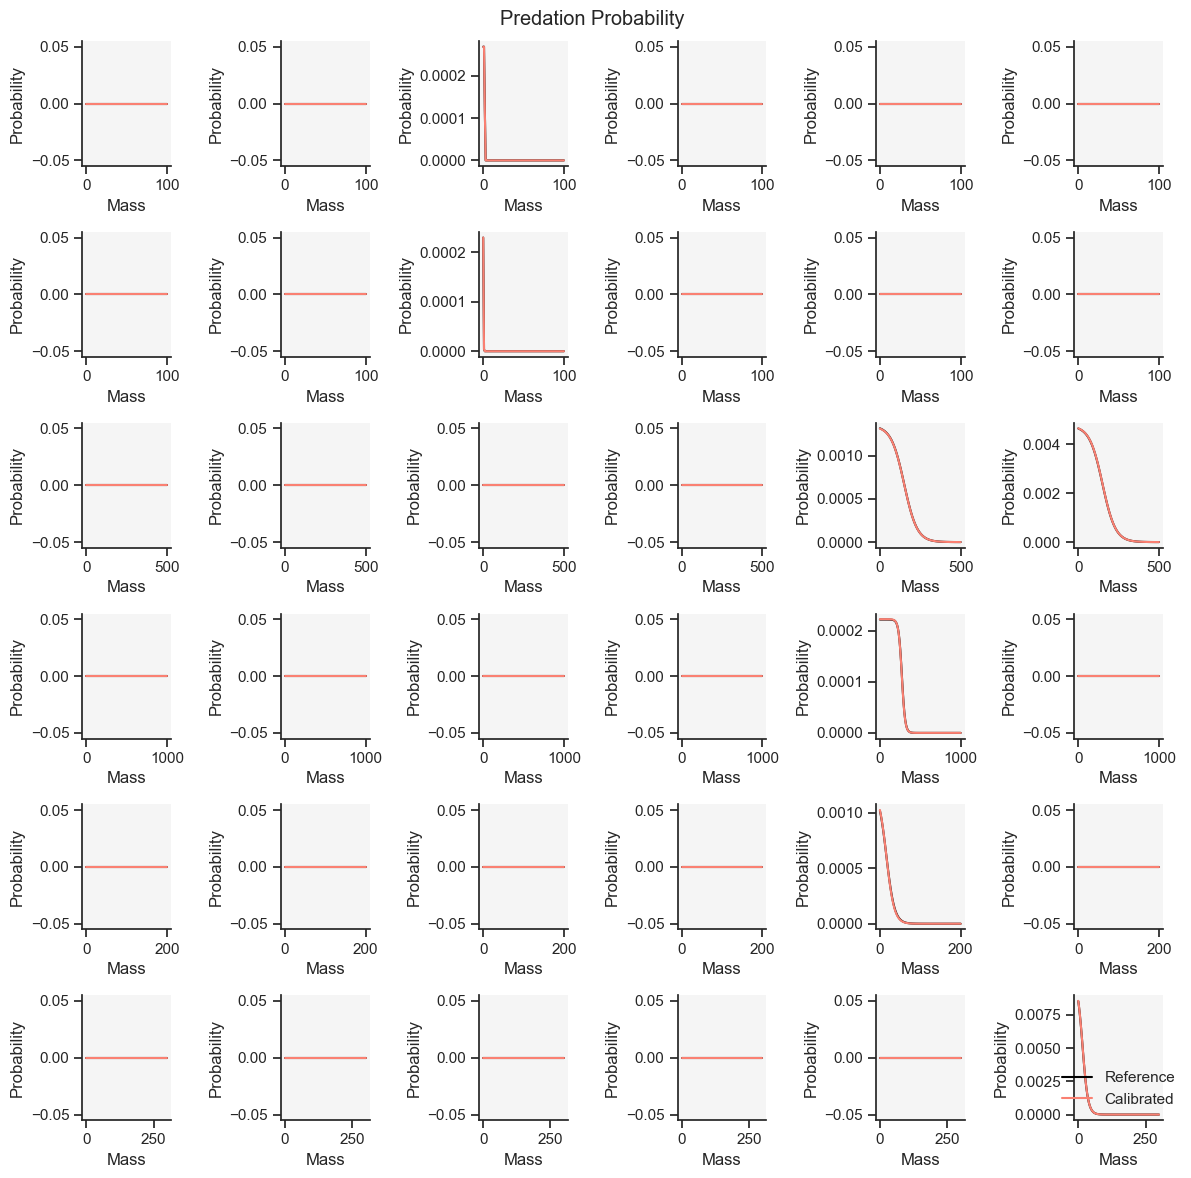

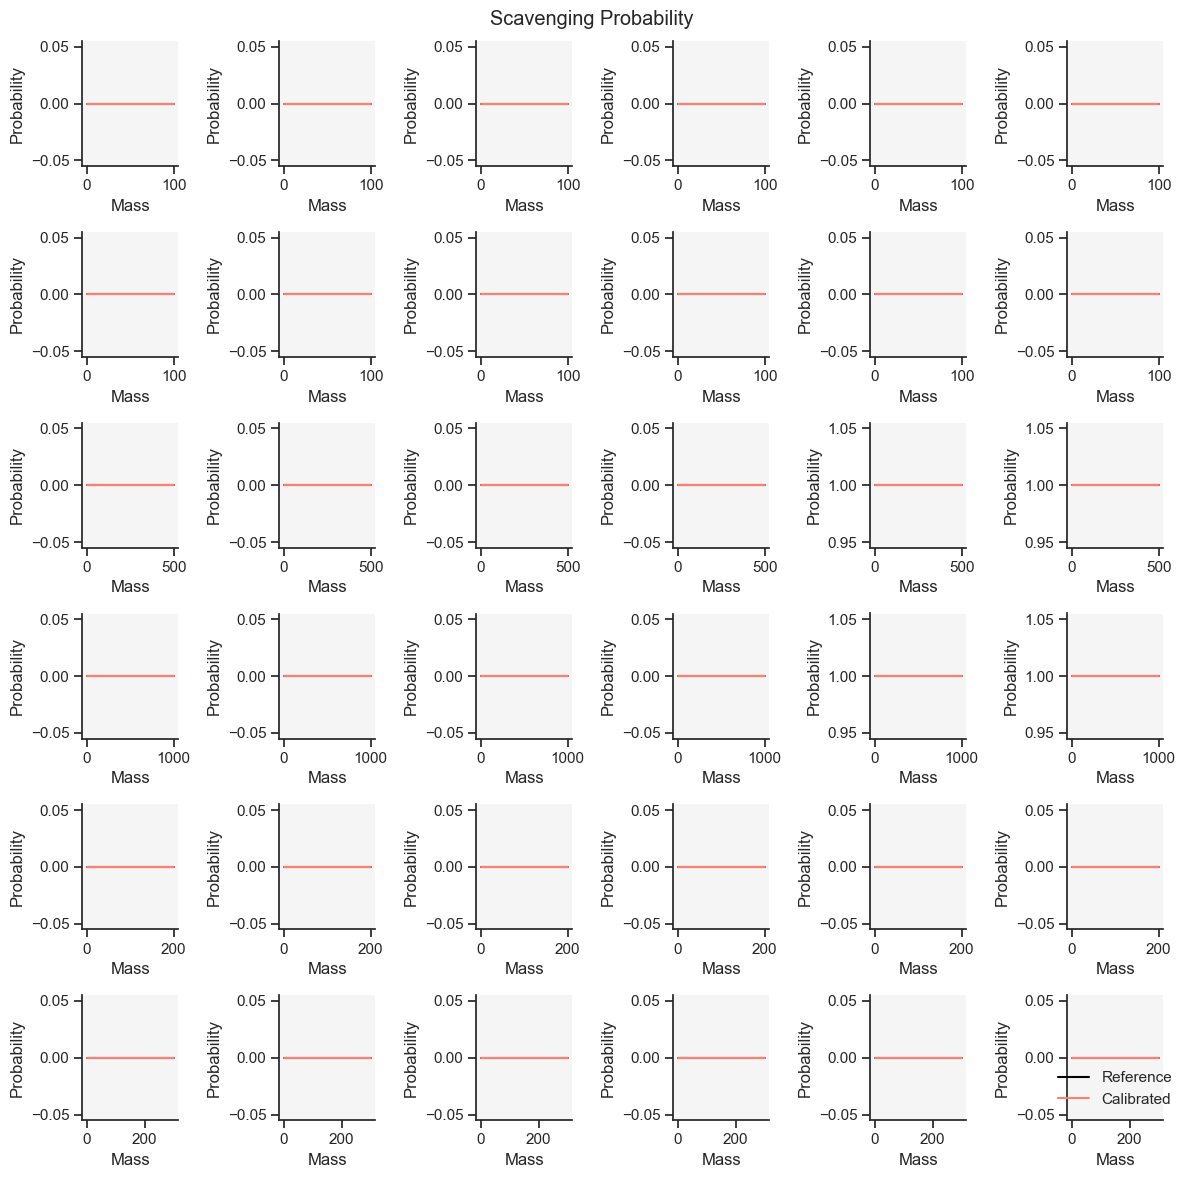

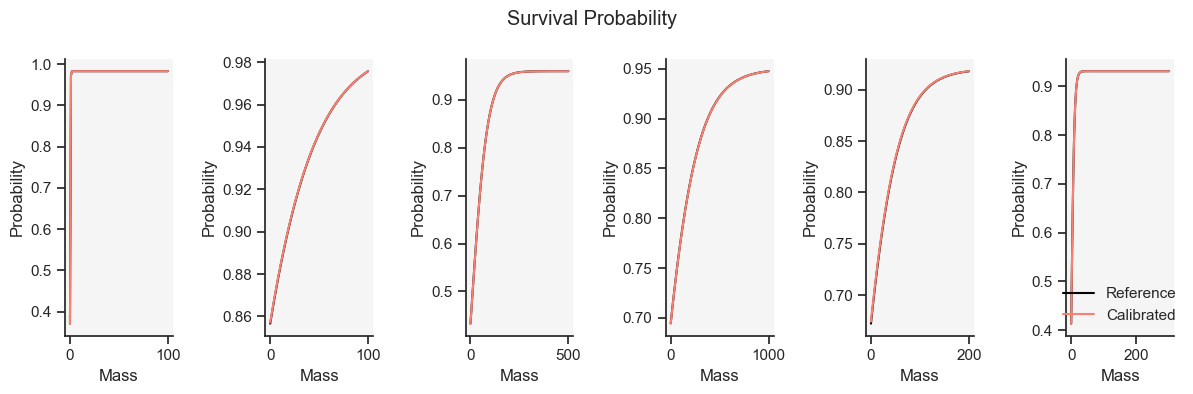

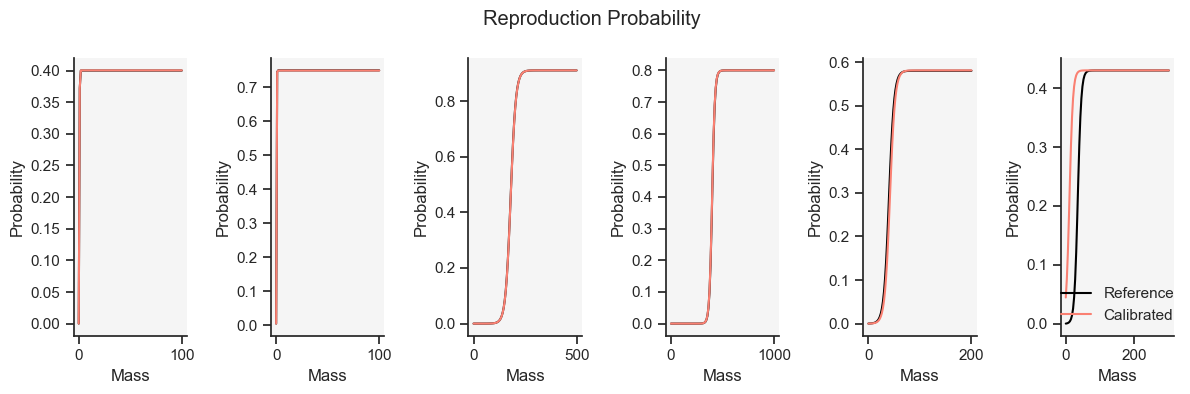

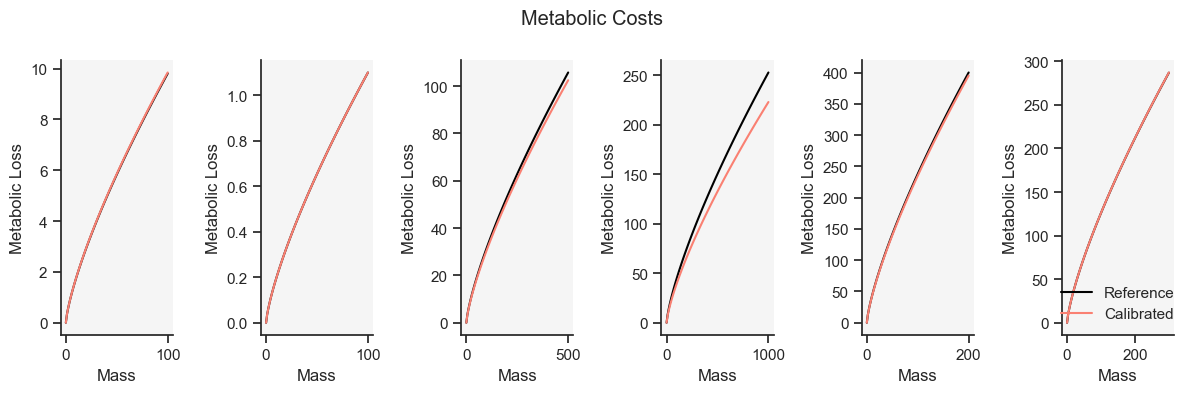

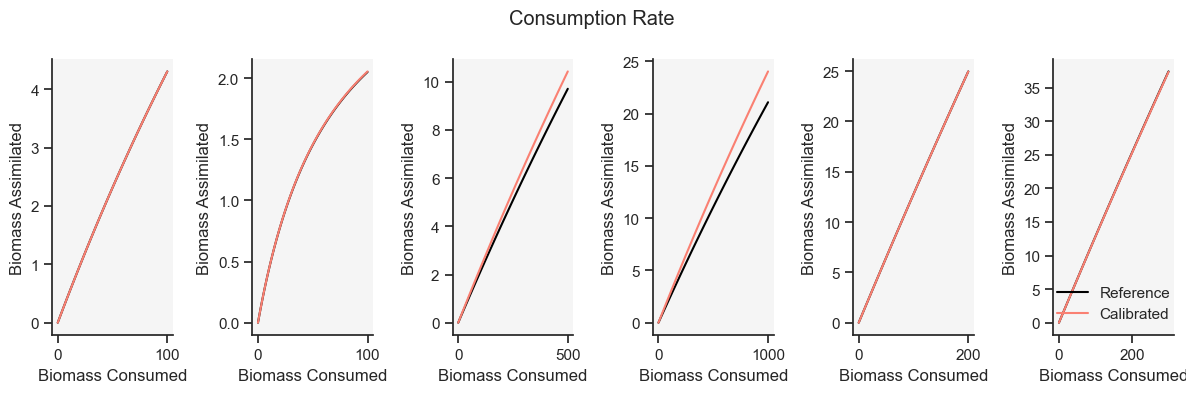

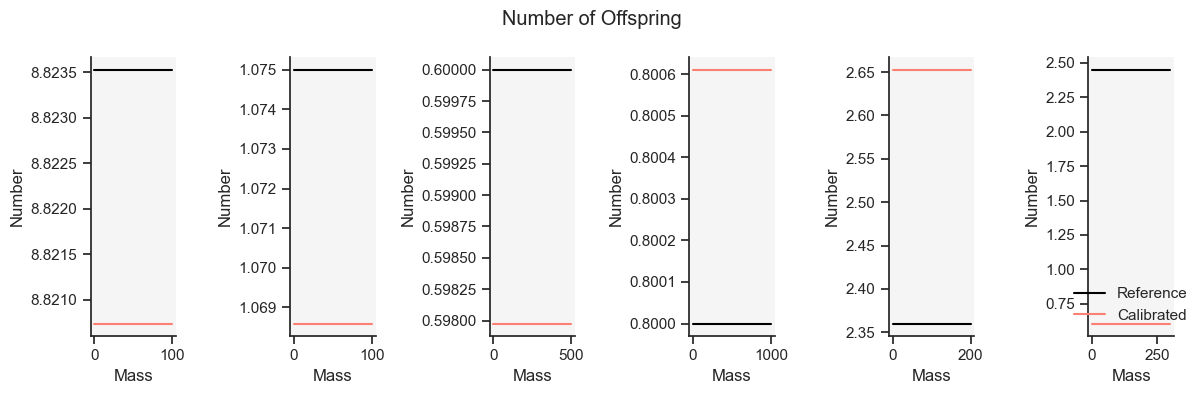

In [23]:
########################################
## VISUALISE DIFFERENCES IN FUNCTIONS ##
########################################

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    b0 = model_r.bbeta_dh0_P[i]    
    yy_r = b0 * torch.ones_like(zz)
    b0 = model_p.bbeta_dh0_P[i]    
    yy_p = b0 * torch.ones_like(zz)
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')
    plt.xlabel('Mass')    
    plt.ylabel('Consumption Rate')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Nutrient Consumption Rate')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    b0 = model_r.bbeta_dh0_G[i]    
    yy_r = b0 * torch.ones_like(zz)
    b0 = model_p.bbeta_dh0_G[i]    
    yy_p = b0 * torch.ones_like(zz)
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')
    plt.xlabel('Mass')    
    plt.ylabel('Consumption Rate')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Grass Consumption Rate')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,12))
k = 0
for i in range(6):
    for j in range(6):
        plt.subplot(6,6,k+1)    
        zz = torch.linspace(0,zzmax[i],100)
        b0 = model_r.bbbeta_dp0[i][j]
        b1 = model_r.bbbeta_dp1[i][j]
        b2 = model_r.bbbeta_dp2[i][j]
        yy_r = b0 * torch.sigmoid((zz - b1) * b2)
        b0 = model_p.bbbeta_dp0[i][j]
        b1 = model_p.bbbeta_dp1[i][j]
        b2 = model_p.bbbeta_dp2[i][j]
        yy_p = b0 * torch.sigmoid((zz - b1) * b2)
        plt.plot(zz, yy_r, label='Reference', color='black')
        plt.plot(zz, yy_p, label='Calibrated', color='salmon')
        plt.xlabel('Mass')    
        plt.ylabel('Probability')    
        k += 1
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Predation Probability')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,12))
k = 0
for i in range(6):
    for j in range(6):
        plt.subplot(6,6,k+1)    
        zz = torch.linspace(0,zzmax[i],100)
        b0 = model_r.bbbeta_dn0[i][j]
        yy_r = b0 * torch.ones_like(zz)
        b0 = model_p.bbbeta_dn0[i][j]
        yy_p = b0 * torch.ones_like(zz)
        plt.plot(zz, yy_r, label='Reference', color='black')
        plt.plot(zz, yy_p, label='Calibrated', color='salmon')
        plt.xlabel('Mass')    
        plt.ylabel('Probability')    
        k += 1
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Scavenging Probability')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    b0 = model_r.bbeta_sn0[i]
    b1 = model_r.bbeta_sn1[i]
    b2 = model_r.bbeta_sn2[i]
    yy_r = b0 * torch.sigmoid((zz - b1) * b2)
    b0 = model_p.bbeta_sn0[i]
    b1 = model_p.bbeta_sn1[i]
    b2 = model_p.bbeta_sn2[i]
    yy_p = b0 * torch.sigmoid((zz - b1) * b2)
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')
    plt.xlabel('Mass')    
    plt.ylabel('Probability')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Survival Probability')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    b0 = model_r.bbeta_b0[i]
    b1 = model_r.bbeta_b1[i]
    b2 = model_r.bbeta_b2[i]
    yy_r = b0 * torch.sigmoid((zz - b1) * b2)
    b0 = model_p.bbeta_b0[i]
    b1 = model_p.bbeta_b1[i]
    b2 = model_p.bbeta_b2[i]
    yy_p = b0 * torch.sigmoid((zz - b1) * b2)
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')
    plt.xlabel('Mass')    
    plt.ylabel('Probability')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Reproduction Probability')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    b0 = model_r.ddelta[i]    
    yy_r = b0 * zz ** 0.75
    b0 = model_p.ddelta[i]
    yy_p = b0 * zz ** 0.75
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')
    plt.xlabel('Mass')    
    plt.ylabel('Metabolic Loss')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Metabolic Costs')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    N_ = 1
    Z_ = zzmax[i]
    b0 = model_r.aalpha_1[i]
    b1 = model_r.aalpha_2[i]
    b2 = model_r.ggamma_1[i]
    b3 = model_r.ggamma_2[i]
    yy_r = b0 * b1 * b2 * b3 * zz / (b2 * N_ + b3 * zz)
    b0 = model_p.aalpha_1[i]
    b1 = model_p.aalpha_2[i]
    b2 = model_p.ggamma_1[i]
    b3 = model_p.ggamma_2[i]
    yy_p = b0 * b1 * b2 * b3 * zz / (b2 * N_ + b3 * zz)
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')    
    plt.xlabel('Biomass Consumed')    
    plt.ylabel('Biomass Assimilated')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Consumption Rate')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)    
    zz = torch.linspace(0,zzmax[i],100)
    b0 = model_r.nnu_o[i]    
    b1 = model_r.mmu_o[i]
    b2 = model_r.bbeta_b1[i]
    yy_r = b0 * torch.ones_like(zz) / b1 * b2
    b0 = model_p.nnu_o[i]    
    b1 = model_p.mmu_o[i]
    b2 = model_p.bbeta_b1[i]
    yy_p = b0 * torch.ones_like(zz) / b1 * b2
    plt.plot(zz, yy_r, label='Reference', color='black')
    plt.plot(zz, yy_p, label='Calibrated', color='salmon')
    plt.xlabel('Mass')    
    plt.ylabel('Number')    
plt.legend(frameon=False, loc='lower center')
plt.suptitle('Number of Offspring')
plt.tight_layout()
plt.show()

#
###